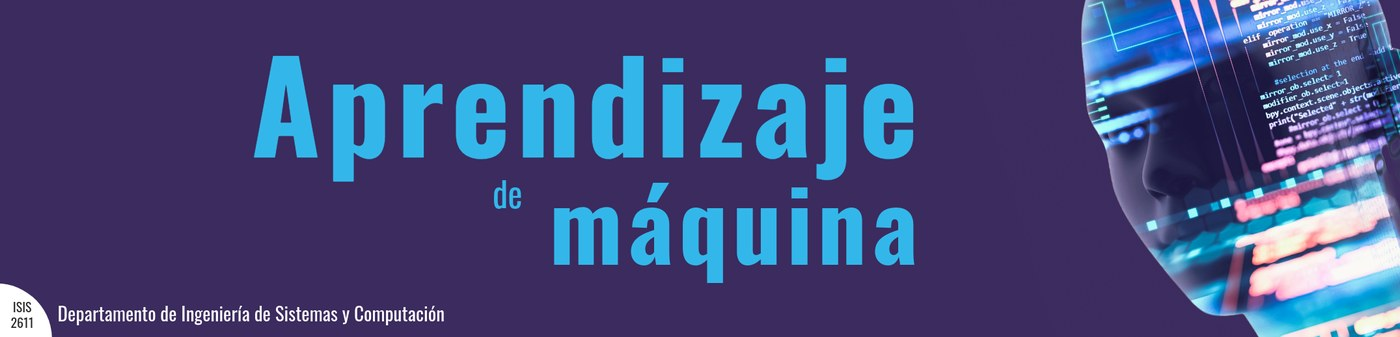

# Agrupación por densidad y jerárquica: DBSCAN y algoritmo aglomerativo

En este tutorial aprenderás a construir modelos de agrupación utilizando dos algoritmos que parten de enfoques diferentes para identificar grupos en los datos:

* **DBSCAN** (agrupación por densidad). Permite identificar grupos a partir de regiones de alta densidad de datos, sin necesidad de definir previamente el número de grupos. Además, permite detectar observaciones aisladas que pueden considerarse ruido.
* **Algoritmo aglomerativo** (agrupación jerárquica). Construye una jerarquía de grupos a partir de las similitudes entre las observaciones. Esta estructura se representa mediante un dendrograma, que permite explorar distintos niveles de agrupación.

Seguimos el mismo mapa del proceso de machine learning: problema → datos → preparación → modelado → evaluación. Utilizaremos un conjunto de datos sobre el comportamiento de clientes con tarjetas de crédito para identificar perfiles según el uso que hacen de ellas.

El notebook cubre los siguientes pasos:

1. Comprensión del problema.
2. Comprensión de los datos.
3. Limpieza y preparación.
4. Modelado con DBSCAN, evaluación e interpretación.
5. Modelado con el algoritmo aglomerativo, evaluación e interpretación.
6. Comparación de los dos modelos.
7. Reflexión sobre sesgos y el modelado
8. Cierre y ejercicios.

## 0. Importación de librerías requeridas

* [`StandardScaler()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html): clase para estandarizar las variables.
* [`DBSCAN()`](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html): clase para crear el modelo de agrupación por densidad.
* [`NearestNeighbors()`](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.NearestNeighbors.html): clase para calcular los vecinos más cercanos de cada dato (la usaremos en el gráfico de k-distancias).
* [`AgglomerativeClustering()`](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html): clase para crear el modelo aglomerativo.
* [`linkage()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html) y [`dendrogram()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.dendrogram.html): funciones de `scipy` para ejecutar el algoritmo aglomerativo y graficar el dendrograma.
* [`silhouette_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html) y [`silhouette_samples()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_samples.html): funciones para calcular el coeficiente de la silueta (métrica interna).
* [`adjusted_rand_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html): función para calcular el índice de Rand ajustado (métrica externa).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.datasets import make_moons, make_blobs
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform

## 1. Comprensión del problema

Un laboratorio de certificación analiza miles de muestras de vino al año. Para cada muestra mide un conjunto de propiedades fisicoquímicas (acidez, azúcar, sulfitos, alcohol, etc.). El laboratorio quiere responder dos preguntas:

1. **¿Las muestras se organizan en grupos naturales según sus propiedades fisicoquímicas?** Si existen perfiles diferenciados, el laboratorio podría definir protocolos de análisis por perfil.
2. **¿Hay muestras atípicas que no se parecen a ningún grupo?** Estas muestras podrían requerir una revisión adicional (errores de medición, vinos inusuales o adulteraciones).

En este caso, lo que buscamos es identificar patrones en los datos y caracterizar grupos de observaciones con características similares, en lugar de predecir una variable objetivo. Por tanto, abordamos el problema como una tarea de agrupación (aprendizaje no supervisado).

El conjunto de datos incluye dos variables adicionales: `color` (tinto o blanco) y `quality` (calificación sensorial). No las usaremos para construir los modelos. Estas nos permitirán hacer una **evaluación externa**, es decir, para verificar a posteriori si los grupos encontrados se relacionan con alguna característica conocida de los vinos.

| Pregunta del laboratorio | Algoritmo que la aborda directamente |
|---|---|
| ¿Existen grupos naturales y cuántos son? | DBSCAN (los descubre según la densidad) y aglomerativo (dendrograma) |
| ¿Cómo se relacionan los grupos entre sí? | Aglomerativo (jerarquía de fusiones) |
| ¿Hay muestras atípicas? | DBSCAN (las etiqueta como ruido) |

<font size="2"> El conjunto de datos que utilizaremos describe muestras de vino tinto y blanco de la variedad portuguesa *Vinho Verde* a partir de atributos fisicoquímicos como el pH, la acidez, el dióxido de azufre o el azúcar residual. Los datos fueron descargados del repositorio UCI ([enlace](https://archive.ics.uci.edu/dataset/186/wine+quality)), y modificados para propósitos de este tutorial. 
Cita: Cortez, P., Cerdeira, A., Almeida, F., Matos, T., and Reis, J. (2009). Wine Quality. UCI Machine Learning Repository. https://doi.org/10.24432/C56S3T.</font>

## 2. Comprensión de los datos

In [2]:
df = pd.read_csv('data/Wine_quality_Data.csv', sep=',')
print(f'El conjunto tiene {df.shape[0]} muestras y {df.shape[1]} variables')

El conjunto tiene 6497 muestras y 13 variables


In [3]:
data = df.copy()

Veamos los primeros datos del conjunto utilizando `head()`:

In [4]:
data.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


### Diccionario de variables

| Variable | Descripción | Unidad |
|---|---|---|
| `fixed_acidity` | Acidez fija | g de ácido tartárico / dm³ |
| `volatile_acidity` | Acidez volátil | g de ácido acético / dm³ |
| `citric_acid` | Ácido cítrico | g / dm³ |
| `residual_sugar` | Azúcar residual | g / dm³ |
| `chlorides` | Cloruros | g de cloruro de sodio / dm³ |
| `free_sulfur_dioxide` | Dióxido de azufre libre | mg / dm³ |
| `total_sulfur_dioxide` | Dióxido de azufre total | mg / dm³ |
| `density` | Densidad | g / cm³ |
| `pH` | pH | — |
| `sulphates` | Sulfatos | g de sulfato de potasio / dm³ |
| `alcohol` | Contenido de alcohol | % vol. |
| `quality` | Calificación sensorial (**no se usa para modelar**) | escala 0–10 |
| `color` | Tipo de vino (**no se usa para modelar**) | `red` / `white` |

Revisemos los tipos de datos y la presencia de valores faltantes con `info()`:

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


Todas las variables fisicoquímicas son numéricas y no hay valores faltantes. Veamos ahora sus estadísticas descriptivas:

In [6]:
data.describe()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


Observa la columna `max` frente a la columna `mean`: las variables tienen **escalas muy distintas**. Por ejemplo, `total_sulfur_dioxide` llega a 440, mientras que `density` varía apenas entre 0.987 y 1.039. Como DBSCAN y el algoritmo aglomerativo se basan en distancias, esta diferencia de escalas será importante en la preparación.

Revisemos también si hay muestras duplicadas, es decir, filas idénticas en todas sus variables:

In [7]:
n_duplicados = data.duplicated().sum()
print(f'Filas duplicadas: {n_duplicados} ({n_duplicados / len(data) * 100:.1f}% del total)')

Filas duplicadas: 1177 (18.1% del total)


Hay un número considerable de filas duplicadas. No son necesariamente errores, pueden corresponder a muestras distintas con mediciones idénticas. Volveremos sobre ellas en la preparación, porque afectan de manera particular a DBSCAN.

Veamos ahora la distribución de cada variable fisicoquímica:

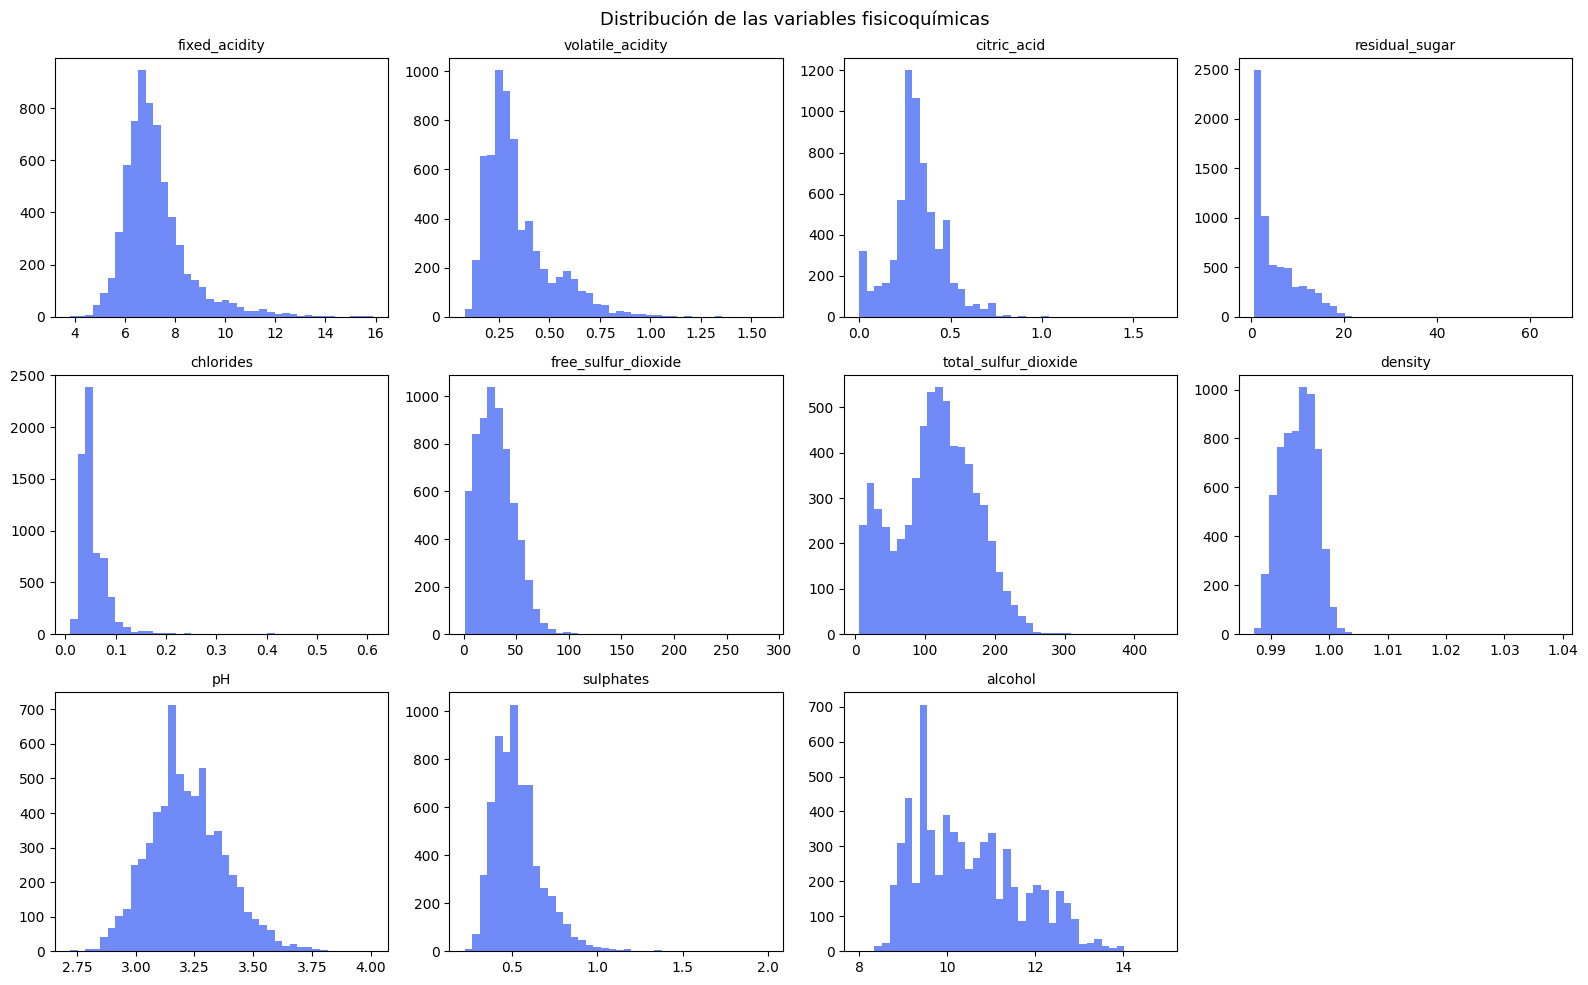

In [8]:
variables = data.columns.drop(['quality', 'color'])

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, variables):
    ax.hist(data[col], bins=40, color='#4C6EF5', alpha=0.8)
    ax.set_title(col, fontsize=10)
axes.flat[-1].axis('off')
plt.suptitle('Distribución de las variables fisicoquímicas', fontsize=13)
plt.tight_layout()
plt.show()

Varias variables son asimétricas y presentan valores extremos (por ejemplo `residual_sugar`, `chlorides` y `free_sulfur_dioxide`). Algunas, como `total_sulfur_dioxide`, muestran más de una moda, lo que sugiere que podrían existir subpoblaciones en los datos.

**Resumen de la exploración de los datos:**
* 11 variables fisicoquímicas numéricas, sin valores faltantes.
* Escalas muy diferentes entre variables.
* Filas duplicadas.
* Distribuciones asimétricas con valores extremos.

## 3. Limpieza y preparación de los datos

Como vimos en la comprensión de los datos, no hay valores faltantes ni variables categóricas entre las variables fisicoquímicas. La preparación consistirá en tratar los duplicados, separar las variables de evaluación externa y escalar.

### 3.1 Tratamiento de los duplicados

En DBSCAN, un dato es **punto núcleo** si su vecindad contiene al menos `min_samples` datos, incluyéndose a sí mismo. Si una muestra aparece repetida varias veces, cada copia cuenta en la vecindad de las demás, de modo que un grupo de duplicados puede convertirse en punto núcleo por sí solo, creando una densidad artificial. 

In [9]:
data = data.drop_duplicates().reset_index(drop=True)
print(f'Muestras después de eliminar duplicados: {len(data)}')

Muestras después de eliminar duplicados: 5320


### 3.2 Separación de las variables de evaluación externa

Separamos las variables fisicoquímicas, que usaremos para modelar, de `color` y `quality`, que usaremos solo para evaluar:

In [10]:
X_original = data[variables]                     # variables fisicoquímicas en su escala original
etiquetas_externas = data[['color', 'quality']]  # solo para evaluación
X_original.shape

(5320, 11)

### 3.3 Escalado

Ambos algoritmos usan la distancia euclidiana. Si no escalamos, las variables con valores grandes (como `total_sulfur_dioxide`) dominarían la distancia y las variables con valores pequeños (como `density`) prácticamente no influirían. Usaremos [`StandardScaler()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html):

In [11]:
scaler = StandardScaler()
X = scaler.fit_transform(X_original)

Con esto termina la preparación. Usaremos `X` (escalado) para entrenar los modelos y `X_original` para interpretar los grupos en las unidades originales.

## 4. Modelado con DBSCAN

### 4.1 ¿Cómo funciona DBSCAN?

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) identifica grupos a partir de la **densidad de los datos**. Utiliza dos hiperparámetros:

- **$\varepsilon$ (`eps`):** radio que define la vecindad de cada punto.
- **$MinPts$ (`min_samples`):** número mínimo de puntos para considerar que una región tiene suficiente densidad, incluido el propio punto.

Sea $D$ el conjunto de datos y $dist(p,q)$ una función de distancia. Los conceptos principales son:

- **$\varepsilon$-vecindad:** conjunto de puntos a una distancia menor o igual que $\varepsilon$ de un punto $p$.
- **Punto núcleo:** tiene al menos $MinPts$ puntos en su $\varepsilon$-vecindad.
- **Punto de borde:** no es núcleo, pero está dentro de la $\varepsilon$-vecindad de algún núcleo.
- **Punto de ruido:** no es núcleo ni de borde.

DBSCAN construye los grupos a partir de los **puntos núcleo** y sus conexiones:

1. Identifica los puntos núcleo, es decir, aquellos que tienen al menos $MinPts$ puntos en su $\varepsilon$-vecindad.
2. Conecta los puntos núcleo cuya distancia es menor o igual que $\varepsilon$. Estas conexiones forman un **grafo**, donde cada componente conexa constituye la estructura central de un clúster.
3. Incorpora a cada clúster los puntos de borde que se encuentran en la $\varepsilon$-vecindad de alguno de sus núcleos.
4. Considera como ruido los puntos que no pertenecen a ningún clúster.

De esta manera, DBSCAN puede identificar **grupos de formas arbitrarias**, sin necesidad de definir previamente su número. Si un punto de borde está asociado a núcleos de distintos clústeres, su asignación puede depender del orden de procesamiento.

### 4.2 Hiperparámetros de DBSCAN y su efecto

DBSCAN tiene dos hiperparámetros que deben definirse antes del entrenamiento. Juntos definen qué significa "región densa": al menos `min_samples` puntos dentro de un radio `eps`.

| Hiperparámetro | Qué controla | Si se aumenta | Si se disminuye |
|---|---|---|---|
| `eps` | Radio de la vecindad de cada punto | Más puntos núcleo y menos ruido; los clústeres tienden a fusionarse | Menos puntos núcleo y más ruido; los clústeres se fragmentan |
| `min_samples` | Número mínimo de puntos en la vecindad para ser núcleo | Se exige más densidad: más ruido y clústeres más robustos | Unos pocos puntos cercanos bastan para formar un clúster, lo que puede crear clústeres espurios |

Los dos hiperparámetros interactúan de la siguiente manera: si aumentamos `min_samples`, necesitamos un `eps` algo mayor para obtener una densidad equivalente. Por eso, en la práctica se parte de un valor de referencia para `min_samples`, que depende sobre todo del número de variables, y con él se estudia la escala de `eps`, que depende de las distancias en los datos.

Veamos el efecto de `eps`, con `min_samples` fijo, en un conjunto sintético en 2D donde podemos ver el resultado directamente. El conjunto tiene tres grupos: uno muy compacto, uno intermedio y uno disperso.

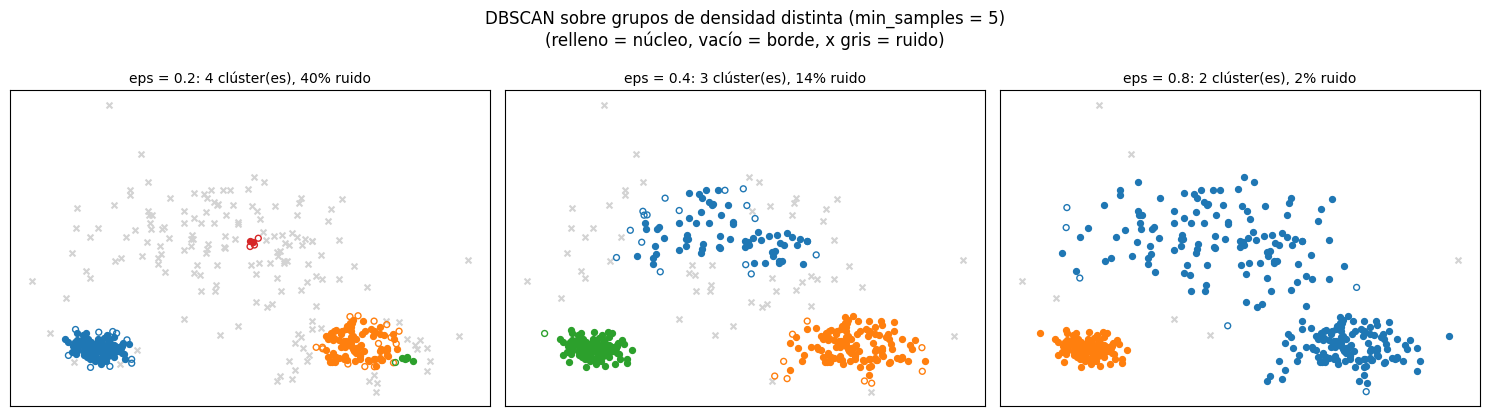

In [12]:
X_densidades, _ = make_blobs(n_samples=400, centers=[[0, 0], [4, 0], [2, 3.5]],
                             cluster_std=[0.25, 0.5, 1.1], random_state=1)
eps_valores = [0.2, 0.4, 0.8]

fig, axes = plt.subplots(1, len(eps_valores), figsize=(15, 4.2))
paleta = plt.cm.tab10(np.arange(10))
for ax, eps in zip(axes, eps_valores):
    modelo = DBSCAN(eps=eps, min_samples=5).fit(X_densidades)
    etiquetas = modelo.labels_
    nucleo = np.zeros(len(X_densidades), dtype=bool)
    nucleo[modelo.core_sample_indices_] = True
    n_clusters = len(set(etiquetas)) - (1 if -1 in etiquetas else 0)
    for c in np.unique(etiquetas):
        m = etiquetas == c
        if c == -1:
            ax.scatter(*X_densidades[m].T, c='lightgray', marker='x', s=18)
        else:
            ax.scatter(*X_densidades[m & nucleo].T, color=paleta[c % 10], s=18)
            ax.scatter(*X_densidades[m & ~nucleo].T, facecolors='none', edgecolors=paleta[c % 10], s=18)
    ax.set_title(f'eps = {eps}: {n_clusters} clúster(es), {np.mean(etiquetas == -1) * 100:.0f}% ruido', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('DBSCAN sobre grupos de densidad distinta (min_samples = 5)\n'
             '(relleno = núcleo, vacío = borde, x gris = ruido)', fontsize=12)
plt.tight_layout()
plt.show()

> **¿Qué observar?**
> * Con `eps` pequeño, los grupos compactos se detectan bien, pero el grupo disperso se declara casi entero como ruido (y aparece algún clúster espurio).
> * Con un valor intermedio se recuperan los tres grupos, aunque parte del grupo disperso sigue siendo ruido.
> * Con `eps` grande, el grupo disperso queda bien cubierto, pero se fusiona con uno de los otros grupos.

DBSCAN usa un único valor de `eps` para todo el conjunto de datos, por lo que no siempre existe un valor adecuado para todos los grupos a la vez. Esta es una limitación conocida de DBSCAN (algoritmos como HDBSCAN y OPTICS se diseñaron para abordarla).

### 4.3 Ajuste de los hiperparámetros


> **Esquema general para ajustar los hiperparámetros de DBSCAN**
> 1. **Heurística para `min_samples`**: un valor de referencia según el número de variables.
> 2. **Heurística para `eps`**: el gráfico de k-distancias, que muestra la escala de las distancias y una cota superior (el codo).
> 3. **Búsqueda en grilla** sobre ambos hiperparámetros, dentro del espacio delimitado por los pasos 1 y 2, comparando los modelos con una métrica (la silueta) junto con criterios propios del problema.
>
> Las heurísticas ayuda a definir el espacio de búsqueda. Sin ellas, la grilla sería ciega, porque la escala adecuada de `eps` depende de los datos (número de variables, escalado). Con ellas, la búsqueda explora una región razonable en lugar de valores arbitrarios.

#### Paso 1. Heurística para `min_samples`

Una heurística frecuente es elegir `min_samples` $\ge d + 1$, donde $d$ es el número de variables, y en la práctica se usa a menudo $2d$. Un valor mayor exige más evidencia para considerar que una región es densa, lo cual es importante en espacios de muchas dimensiones, donde los datos tienden a estar más dispersos (recuerda la *maldición de la dimensionalidad* vista con KNN). Tomaremos $2d$ como referencia y, para la búsqueda, exploraremos también un valor menor ($d+1$, el mínimo de la heurística) y uno mayor ($3d$):

In [13]:
d = X.shape[1]
min_samples_base = 2 * d                     # valor de referencia
min_samples_list = [d + 1, 2 * d, 3 * d]     # rango para la búsqueda en grilla
print(f'Número de variables: {d}')
print(f'min_samples de referencia: {min_samples_base}')
print(f'Valores de min_samples para la búsqueda: {min_samples_list}')

Número de variables: 11
min_samples de referencia: 22
Valores de min_samples para la búsqueda: [12, 22, 33]


#### Paso 2. Heurística para `eps`: gráfico de k-distancias

Para cada observación calculamos la distancia a su vecino número `min_samples` (incluida la propia observación) y ordenamos los valores. Un cambio marcado en la curva puede orientar `eps`, **pero no garantiza una buena agrupación**. La estimación automática del codo que usamos es solo exploratoria.

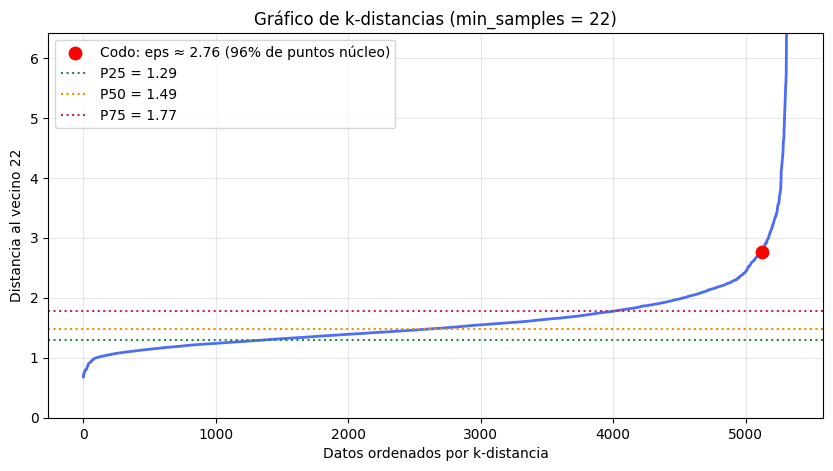

In [14]:
def grafico_k_distancias(X, min_samples):
    '''
    Grafica las k-distancias ordenadas y estima el codo de la curva

    Parametros:
    X : np.array
        El arreglo con los datos escalados
    min_samples : int
        Valor de min_samples (el conteo incluye al propio punto)
    Retorna:
    dist_k : np.array con las k-distancias ordenadas
    eps_codo : float con el valor de eps en el codo
    '''
    vecinos = NearestNeighbors(n_neighbors=min_samples).fit(X)
    distancias, _ = vecinos.kneighbors(X)
    dist_k = np.sort(distancias[:, -1])

    # Codo: punto más alejado de la recta entre el primer y el último punto (en escala normalizada)
    x_norm = np.linspace(0, 1, len(dist_k))
    y_norm = (dist_k - dist_k.min()) / (dist_k.max() - dist_k.min())
    idx_codo = np.argmax(x_norm - y_norm)
    eps_codo = dist_k[idx_codo]

    plt.figure(figsize=(10, 5))
    plt.plot(dist_k, color='#4C6EF5', lw=2)
    plt.scatter(idx_codo, eps_codo, color='red', s=80, zorder=3,
                label=f'Codo: eps ≈ {eps_codo:.2f} ({(idx_codo + 1) / len(dist_k) * 100:.0f}% de puntos núcleo)')
    for p, color_p in zip([25, 50, 75], ['#2B8A3E', '#F08C00', '#C2255C']):
        plt.axhline(np.percentile(dist_k, p), color=color_p, linestyle=':', lw=1.5,
                    label=f'P{p} = {np.percentile(dist_k, p):.2f}')
    # Limitamos el eje vertical: unos pocos datos muy aislados tienen k-distancias enormes
    plt.ylim(0, np.percentile(dist_k, 99.5) * 1.3)
    plt.xlabel('Datos ordenados por k-distancia')
    plt.ylabel(f'Distancia al vecino {min_samples}')
    plt.title(f'Gráfico de k-distancias (min_samples = {min_samples})')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
    return dist_k, eps_codo

dist_k, eps_codo = grafico_k_distancias(X, min_samples_base)

El codo orienta la **escala de las distancias**, pero no determina el mejor `eps` ya núcleos conectados pueden unir regiones diferentes. Exploraremos valores cercanos y menores, sin tratar el codo como una cota universal.

Usaremos el gráfico para definir el rango de `eps` de la búsqueda:
* **Límite inferior**: el percentil 10 de las k-distancias. Con valores menores, menos del 10% de los datos serían núcleo y la mayoría quedaría como ruido.
* **Límite superior**: el codo, porque con valores mayores casi todos los datos son núcleo y los grupos se fusionan.

In [15]:
eps_min = np.floor(np.percentile(dist_k, 10) * 10) / 10   # redondeamos hacia abajo a un decimal
eps_max = np.ceil(eps_codo * 10) / 10                      # redondeamos hacia arriba a un decimal
eps_list = np.round(np.arange(eps_min, eps_max + 0.001, 0.1), 2)
print(f'Rango de eps para la búsqueda: de {eps_min} a {eps_max} ({len(eps_list)} valores)')

Rango de eps para la búsqueda: de 1.1 a 2.8 (18 valores)


#### Paso 3. Búsqueda en grilla

Con el espacio de búsqueda delimitado por las heurísticas, entrenamos un modelo DBSCAN por cada combinación de `eps` y `min_samples`. Es la misma idea de la búsqueda en grilla del aprendizaje supervisado, con una diferencia importante: allí los modelos se comparan con una métrica calculada sobre datos de validación con etiquetas; aquí no hay etiquetas, así que la métrica es **interna** (la silueta) y, como veremos, no basta por sí sola.

Para cada combinación registraremos varios resultados. Ninguno de ellos es una entrada del modelo.

* **Clústeres encontrados**: los descubre DBSCAN; no se le indica cuántos debe encontrar.
* **% ruido**: porcentaje de datos que no pertenecen a ningún clúster.
* **% clúster menor**: porcentaje de datos en el clúster más pequeño (para detectar clústeres triviales de muy pocos datos).
* **Silueta (sin ruido)**: calculada sin los puntos de ruido, porque el ruido no es un clúster y no tiene sentido medir qué tan compacto es.

In [16]:
def busqueda_dbscan(X, eps_list, min_samples_list):
    '''
    Entrena DBSCAN para cada combinación de (eps, min_samples) y registra medidas de resultado

    Parametros:
    X : np.array
        El arreglo con los datos escalados
    eps_list : list
        Valores de eps a evaluar
    min_samples_list : list
        Valores de min_samples a evaluar
    Retorna:
    pd.DataFrame con una fila por combinación
    '''
    filas = []
    for min_samples in min_samples_list:
        for eps in eps_list:
            etiquetas = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
            no_ruido = etiquetas != -1
            clusters, tamanos = np.unique(etiquetas[no_ruido], return_counts=True)
            n_clusters = len(clusters)
            # La silueta solo está definida si hay al menos 2 clústeres
            silueta = silhouette_score(X[no_ruido], etiquetas[no_ruido]) if n_clusters > 1 else np.nan
            filas.append({
                'eps': round(eps, 2),
                'min_samples': min_samples,
                'clústeres encontrados': n_clusters,
                '% ruido': round((~no_ruido).mean() * 100, 1),
                # Solo tiene sentido hablar del clúster "menor" si hay al menos 2 clústeres
                '% clúster menor': round(tamanos.min() / len(X) * 100, 1) if n_clusters > 1 else np.nan,
                'silueta (sin ruido)': round(silueta, 3)
            })
    return pd.DataFrame(filas)

def mostrar_busqueda(df):
    '''
    Retorna una copia de la tabla de resultados con las columnas agrupadas en
    "Hiperparámetros" (entradas del modelo) y "Resultados" (salidas del modelo)
    '''
    tabla = df.copy()
    tabla.columns = pd.MultiIndex.from_tuples(
        [('Hiperparámetros', c) if c in ['eps', 'min_samples'] else ('Resultados', c) for c in df.columns])
    return tabla

# eps_list y min_samples_list vienen de las heurísticas de los pasos 1 y 2
resultados_dbscan = busqueda_dbscan(X, eps_list, min_samples_list)
print(f'Modelos entrenados: {len(resultados_dbscan)}')

Modelos entrenados: 54


Visualicemos cómo cambian el número de clústeres y el porcentaje de ruido en función de `eps`. 

In [17]:
mostrar_busqueda(resultados_dbscan.sort_values('silueta (sin ruido)', ascending=False).head(8))

Hiperparámetros                        Resultados                          \
               eps min_samples clústeres encontrados % ruido % clúster menor   
15             2.6          12                     2     1.1             0.2   
16             2.7          12                     2     0.9             0.2   
17             2.8          12                     2     0.8             0.2   
36             1.1          33                     3    85.5             1.4   
37             1.2          33                     2    69.8             4.7   
18             1.1          22                     4    76.0             0.4   
38             1.3          33                     2    51.6             7.6   
2              1.3          12                     2    29.4            14.6   

                        
   silueta (sin ruido)  
15               0.626  
16               0.625  
17               0.624  
36               0.499  
37               0.428  
18               0.395  
38               0.355  
2                0.298

Observa tres cosas:

* El porcentaje de ruido disminuye de forma suave al aumentar `eps`, pero el número de clústeres cambia de forma **irregular**.
* Con `eps` pequeño aparecen muchos clústeres, pero casi todos son diminutos y la mayoría de los datos es ruido.
* El tercer gráfico muestra que solo en una **ventana estrecha** de `eps` (alrededor de 1.3–1.4) aparecen dos clústeres en los que el más pequeño tiene un tamaño apreciable. Un poco más allá, esos dos clústeres se fusionan. Con valores grandes de `eps` vuelven a aparecer "dos clústeres", pero el segundo tiene muy pocos datos.

Como criterio **ilustrativo**, exigiremos al menos dos grupos, un grupo menor con 5 % de los datos y no más de 30 % de ruido. Estos umbrales deben ajustarse según el objetivo del problema.

In [18]:
candidatos = resultados_dbscan[
    (resultados_dbscan['clústeres encontrados'] >= 2) &
    (resultados_dbscan['% clúster menor'] >= 5) &
    (resultados_dbscan['% ruido'] <= 30)
].sort_values('silueta (sin ruido)', ascending=False)
mostrar_busqueda(candidatos)

Hiperparámetros                        Resultados                          \
               eps min_samples clústeres encontrados % ruido % clúster menor   
2              1.3          12                     2    29.4            14.6   
21             1.4          22                     2    27.7            14.6   

                        
   silueta (sin ruido)  
2                0.298  
21               0.296

Seleccionaremos el candidato con mayor silueta entre los que cumplen los criterios. Comprueba en la tabla cuántas combinaciones cumplen y qué diferencias presentan.

### 4.4 Entrenamiento del modelo final

In [19]:
mejor_eps = candidatos.iloc[0]['eps']
mejor_min_samples = int(candidatos.iloc[0]['min_samples'])

modelo_dbscan = DBSCAN(eps=mejor_eps, min_samples=mejor_min_samples)
etiquetas_dbscan = modelo_dbscan.fit_predict(X)

n_nucleo = len(modelo_dbscan.core_sample_indices_)
n_ruido = np.sum(etiquetas_dbscan == -1)
print(f'Modelo DBSCAN: eps = {mejor_eps}, min_samples = {mejor_min_samples}')
print(f'Puntos núcleo: {n_nucleo} | Puntos borde: {len(X) - n_nucleo - n_ruido} | Ruido: {n_ruido}')

Modelo DBSCAN: eps = 1.3, min_samples = 12
Puntos núcleo: 2328 | Puntos borde: 1428 | Ruido: 1564


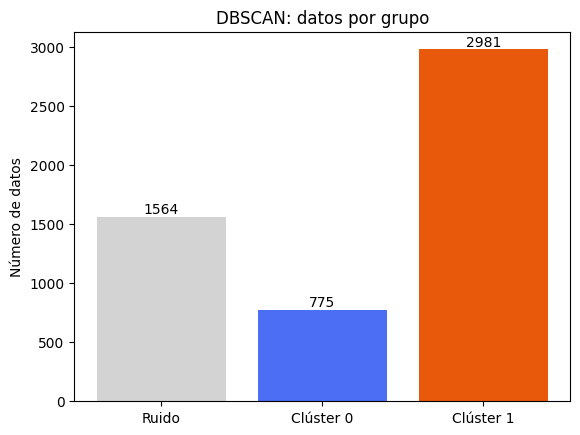

In [20]:
valores, conteos = np.unique(etiquetas_dbscan, return_counts=True)
nombres = ['Ruido' if v == -1 else f'Clúster {v}' for v in valores]

barras = plt.bar(nombres, conteos, color=['lightgray'] + ['#4C6EF5', '#E8590C', '#2B8A3E'][:len(valores) - 1])
plt.bar_label(barras)
plt.ylabel('Número de datos')
plt.title('DBSCAN: datos por grupo')
plt.show()

### 4.5. Evaluación del modelo DBSCAN

Evaluaremos el modelo de tres maneras: con una **métrica interna** (silueta) y con una **métrica externa** (comparando con `color`) 

**Evaluación interna**: coeficiente de la silueta.

Definiremos la función `grafico_silueta()`, que muestra el coeficiente de cada dato agrupado por clúster. La reutilizaremos más adelante con el algoritmo aglomerativo. Los puntos de ruido se excluyen del cálculo:

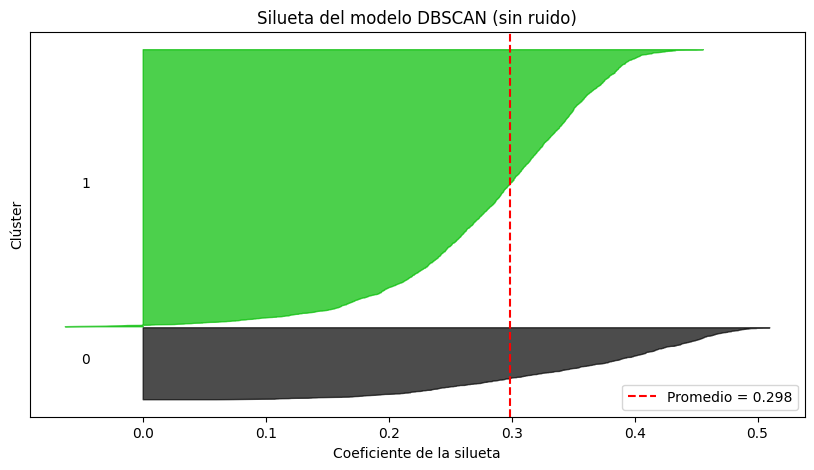

In [21]:
def grafico_silueta(X, etiquetas, titulo):
    '''
    Genera la gráfica con el coeficiente de la silueta para cada dato, agrupado por clúster.
    Los datos con etiqueta -1 (ruido) se excluyen.

    Parametros:
    X : np.array
        El arreglo con los datos
    etiquetas : np.array
        Etiquetas de clúster de cada dato
    titulo : str
        Título de la gráfica
    '''
    mascara = etiquetas != -1
    X_c, etq = X[mascara], etiquetas[mascara]
    valores_silueta = silhouette_samples(X_c, etq)
    promedio = valores_silueta.mean()
    clusters = np.unique(etq)

    plt.figure(figsize=(10, 5))
    y_inferior = 10
    for i, c in enumerate(clusters):
        valores_c = np.sort(valores_silueta[etq == c])
        y_superior = y_inferior + len(valores_c)
        color = cm.nipy_spectral(float(i) / len(clusters))
        plt.fill_betweenx(np.arange(y_inferior, y_superior), 0, valores_c,
                          facecolor=color, edgecolor=color, alpha=0.7)
        plt.text(-0.05, y_inferior + 0.5 * len(valores_c), str(c))
        y_inferior = y_superior + 10
    plt.axvline(promedio, color='red', linestyle='--', label=f'Promedio = {promedio:.3f}')
    plt.xlabel('Coeficiente de la silueta')
    plt.ylabel('Clúster')
    plt.yticks([])
    plt.title(titulo)
    plt.legend()
    plt.show()
    return promedio

silueta_dbscan = grafico_silueta(X, etiquetas_dbscan, 'Silueta del modelo DBSCAN (sin ruido)')

Un coeficiente promedio alrededor de 0.3 indica una estructura **débil o moderada**: los grupos existen, pero no están muy separados. Recuerda además que al excluir el ruido estamos dejando fuera precisamente los datos más difíciles de asignar, por lo que esta silueta es **optimista** si la comparamos con la de un algoritmo que asigna todos los datos.

**Evaluación externa**: ¿los grupos se relacionan con el color del vino?

Aunque no usamos `color` para entrenar, podemos verificar si los grupos coinciden con él. Usaremos una **tabla de contingencia** y el **índice de Rand ajustado** (ARI), que vale 1 cuando las dos particiones coinciden perfectamente y cerca de 0 cuando la coincidencia no es mejor que una asignación aleatoria:

In [22]:
color = etiquetas_externas['color'].values
tabla_dbscan = pd.crosstab(pd.Series(etiquetas_dbscan, name='Grupo DBSCAN').replace(-1, 'Ruido'),
                           pd.Series(color, name='color'))
display(tabla_dbscan)

no_ruido = etiquetas_dbscan != -1
ari_dbscan_todos = adjusted_rand_score(color, etiquetas_dbscan)
ari_dbscan_sin_ruido = adjusted_rand_score(color[no_ruido], etiquetas_dbscan[no_ruido])
print(f'ARI con todos los datos (el ruido cuenta como un grupo): {ari_dbscan_todos:.3f}')
print(f'ARI solo con los datos agrupados (sin ruido):           {ari_dbscan_sin_ruido:.3f}')

color,red,white
Grupo DBSCAN,,
0,770,5
1,7,2974
Ruido,582,982


ARI con todos los datos (el ruido cuenta como un grupo): 0.456
ARI solo con los datos agrupados (sin ruido):           0.986


Compara los grupos con `color`, una variable que **no se utilizó para entrenar**. El ARI mide concordancia con esa etiqueta externa; no determina por sí solo si los perfiles son útiles para el laboratorio. El ruido puede incluir casos extremos o poco representados, no necesariamente ambiguos.

### 4.6 Interpretación de los grupos

Para describir cada grupo usaremos diagramas de caja de las variables en su **escala original**:

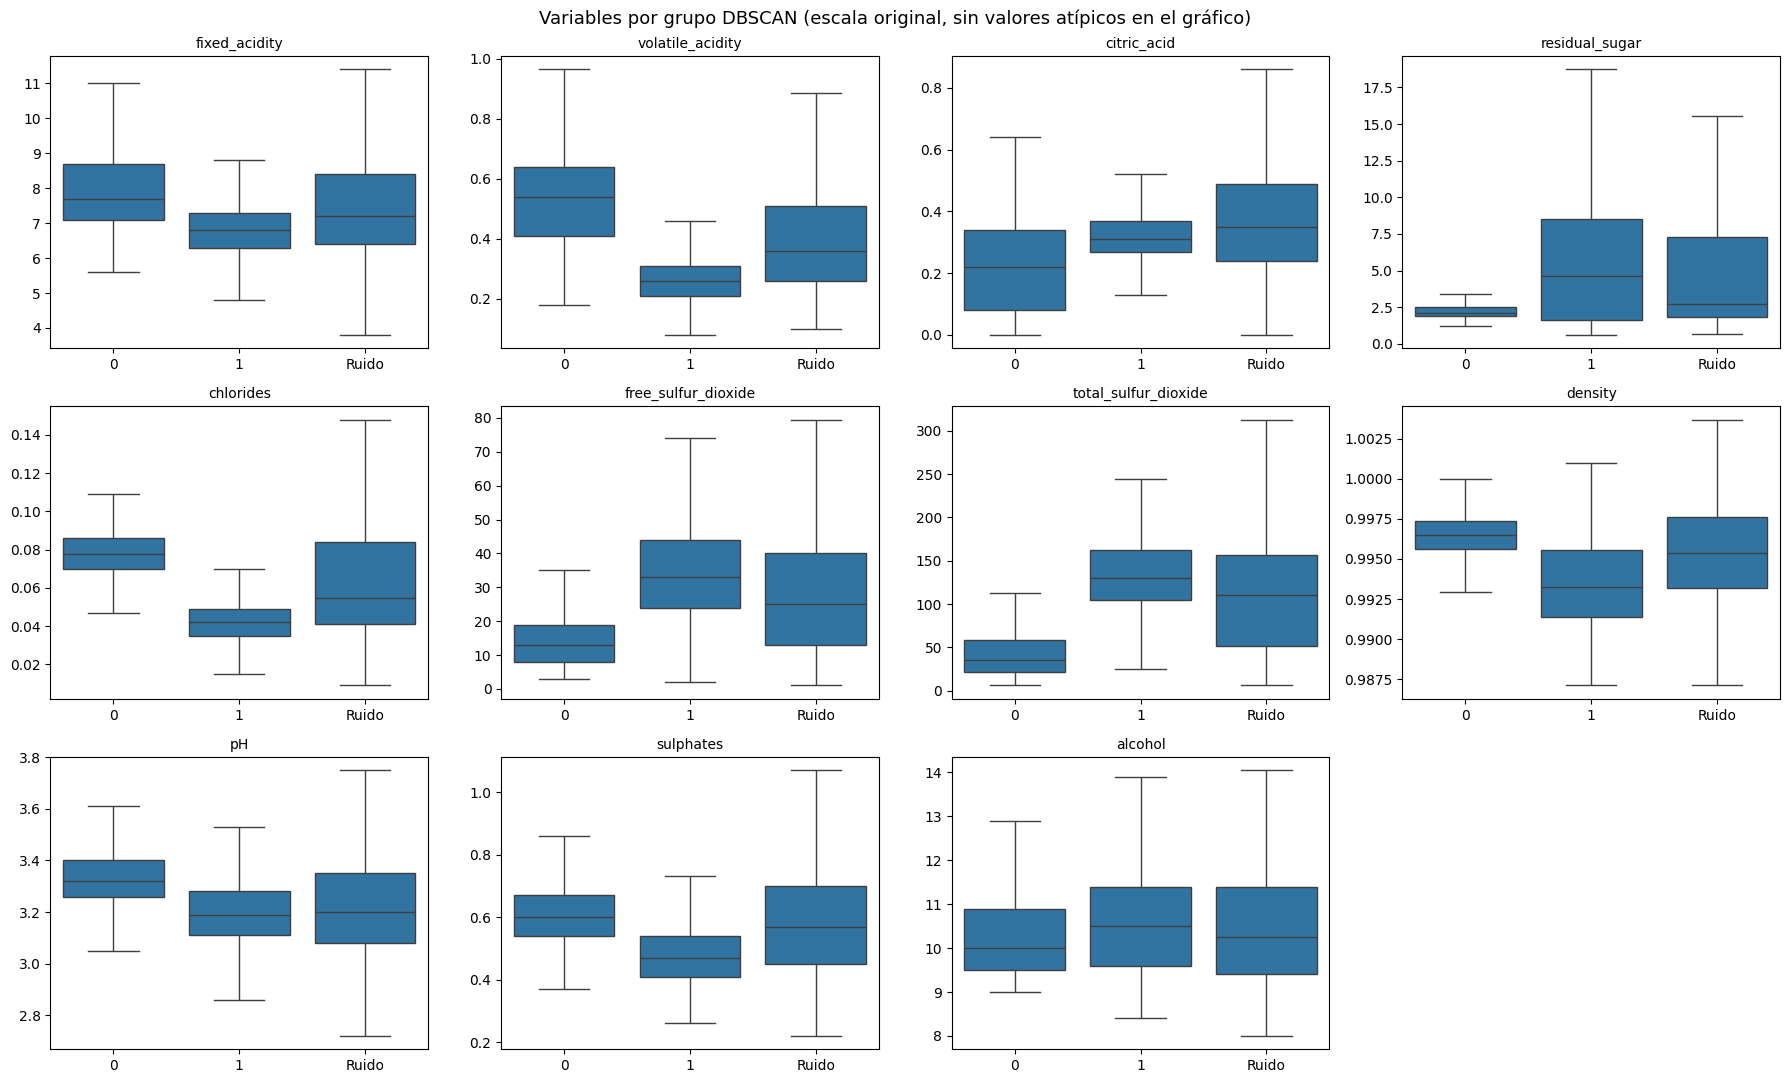

In [23]:
def boxplots_por_grupo(X_original, etiquetas, titulo):
    '''
    Genera un diagrama de cajas por variable, comparando los grupos

    Parametros:
    X_original : pd.DataFrame
        Variables en su escala original
    etiquetas : np.array
        Etiquetas de clúster de cada dato (-1 se muestra como "Ruido")
    titulo : str
        Título general de la figura
    '''
    df = X_original.copy()
    df['Grupo'] = pd.Series(etiquetas).replace(-1, 'Ruido').astype(str).values
    orden = sorted(df['Grupo'].unique(), key=lambda g: (g == 'Ruido', g))
    fig, axes = plt.subplots(3, 4, figsize=(18, 11))
    for ax, col in zip(axes.flat, X_original.columns):
        sns.boxplot(data=df, x='Grupo', y=col, order=orden, ax=ax, showfliers=False)
        ax.set_title(col, fontsize=10); ax.set_xlabel(''); ax.set_ylabel('')
    axes.flat[-1].axis('off')
    plt.suptitle(titulo, fontsize=13)
    plt.tight_layout()
    plt.show()

boxplots_por_grupo(X_original, etiquetas_dbscan, 'Variables por grupo DBSCAN (escala original, sin valores atípicos en el gráfico)')

Complementemos los diagramas con la mediana de cada variable por grupo:

In [24]:
medianas_dbscan = X_original.groupby(pd.Series(etiquetas_dbscan, name='Grupo').replace(-1, 'Ruido')).median().T
medianas_dbscan.round(3)

Grupo,0,1,Ruido
fixed_acidity,7.700,6.800,7.200
volatile_acidity,0.540,0.260,0.360
citric_acid,0.220,0.310,0.350
residual_sugar,2.100,4.600,2.700
chlorides,0.078,0.042,0.055
free_sulfur_dioxide,13.000,33.000,25.000
total_sulfur_dioxide,35.000,130.000,110.000
density,0.996,0.993,0.995
pH,3.320,3.190,3.200
sulphates,0.600,0.470,0.570


> **Para interpretar** (compara con los diagramas de caja y la tabla de medianas):
> * ¿Qué variables diferencian más claramente a los dos clústeres? Fíjate, por ejemplo, en `total_sulfur_dioxide`, `chlorides`, `volatile_acidity` y `residual_sugar`.
> * ¿Cómo se comparan las cajas del grupo **Ruido** con las de los clústeres? ¿Son valores intermedios entre los dos grupos, valores extremos, o ambos?
> * Con base en la tabla de contingencia, ¿qué proporción de los vinos tintos y de los blancos quedó marcada como ruido? ¿Qué podría significar para el laboratorio?

## 5. Modelado con el algoritmo aglomerativo

### 5.1 ¿Cómo funciona el algoritmo aglomerativo?

El algoritmo aglomerativo sigue un enfoque **de abajo hacia arriba**:

1. **Inicio**: cada dato es su propio clúster ($N$ clústeres).
2. **Fusión**: en cada iteración se fusionan los dos clústeres más cercanos según un **criterio de enlace**.
3. **Final**: el proceso termina cuando queda un único clúster. El resultado es una jerarquía de $N-1$ fusiones.

El punto de partida es la **matriz de distancias** entre todos los pares de datos. Veamos un ejemplo con cinco puntos:

In [25]:
X_mini = np.array([[1.0, 1.0], [1.5, 1.2], [5.0, 5.0], [5.5, 4.6], [9.0, 1.0]])
nombres_mini = ['A', 'B', 'C', 'D', 'E']
matriz_dist = pd.DataFrame(squareform(pdist(X_mini, metric='euclidean')),
                           index=nombres_mini, columns=nombres_mini)
matriz_dist.round(2)

,A,B,C,D,E
A,0.00,0.54,5.66,5.76,8.00
B,0.54,0.00,5.17,5.25,7.50
C,5.66,5.17,0.00,0.64,5.66
D,5.76,5.25,0.64,0.00,5.02
E,8.00,7.50,5.66,5.02,0.00


La matriz es simétrica y tiene ceros en la diagonal. Su tamaño es $N \times N$, por lo que el algoritmo aglomerativo requiere memoria del orden de $O(N^2)$: con muchos datos se vuelve costoso.

### 5.2 Criterios de enlace

Una vez que un clúster tiene más de un dato, necesitamos definir la distancia **entre dos clústeres** $A$ y $B$. Ese es el criterio de enlace (`linkage`):

| Enlace | Distancia entre clústeres | Comportamiento típico |
|---|---|---|
| `single` | $d(A,B) = \min_{a \in A,\, b \in B} d(a,b)$ | Forma cadenas largas (*efecto cadena*); sensible al ruido |
| `complete` | $d(A,B) = \max_{a \in A,\, b \in B} d(a,b)$ | Clústeres compactos; sensible a valores extremos |
| `average` | $d(A,B) = \frac{1}{\lvert A\rvert \lvert B\rvert}\sum_{a \in A}\sum_{b \in B} d(a,b)$ | Compromiso entre los dos anteriores |
| `ward` | $\Delta(A,B) = \frac{\lvert A\rvert \lvert B\rvert}{\lvert A\rvert + \lvert B\rvert}\,\lVert \mu_A - \mu_B \rVert^2$ | Clústeres compactos y de tamaño similar |

En `ward`, $\Delta(A,B)$ es el **aumento de la suma de distancias al cuadrado dentro de los clústeres** (la inercia que estudiaste con K-medias) que produce fusionar $A$ y $B$; en cada paso se elige la fusión que menos la aumenta. Es una estrategia voraz, por lo que no garantiza el mismo resultado que K-medias. `ward` solo puede usarse con distancia euclidiana.

### 5.3 ¿Qué es un dendrograma y cómo se lee?

El dendrograma representa la jerarquía de fusiones:
* **Eje horizontal**: los datos (o grupos de datos).
* **Eje vertical**: la distancia a la que se fusionaron dos clústeres (según el criterio de enlace).
* Cada unión en forma de "U" es una fusión. Las uniones altas fusionan clústeres muy distintos.

Para elegir el número de clústeres buscamos el **mayor salto vertical entre dos fusiones consecutivas**: indica que pasamos de fusionar grupos cercanos a fusionar grupos lejanos. Si cortamos con una línea horizontal dentro de ese salto, el número de ramas que cruza la línea es el número de clústeres sugerido. Si $h_1 \le h_2 \le \dots \le h_{N-1}$ son las alturas de las fusiones, cortar entre $h_{i}$ y $h_{i+1}$ deja $N - i$ clústeres.

Veamos un ejemplo con ocho puntos:

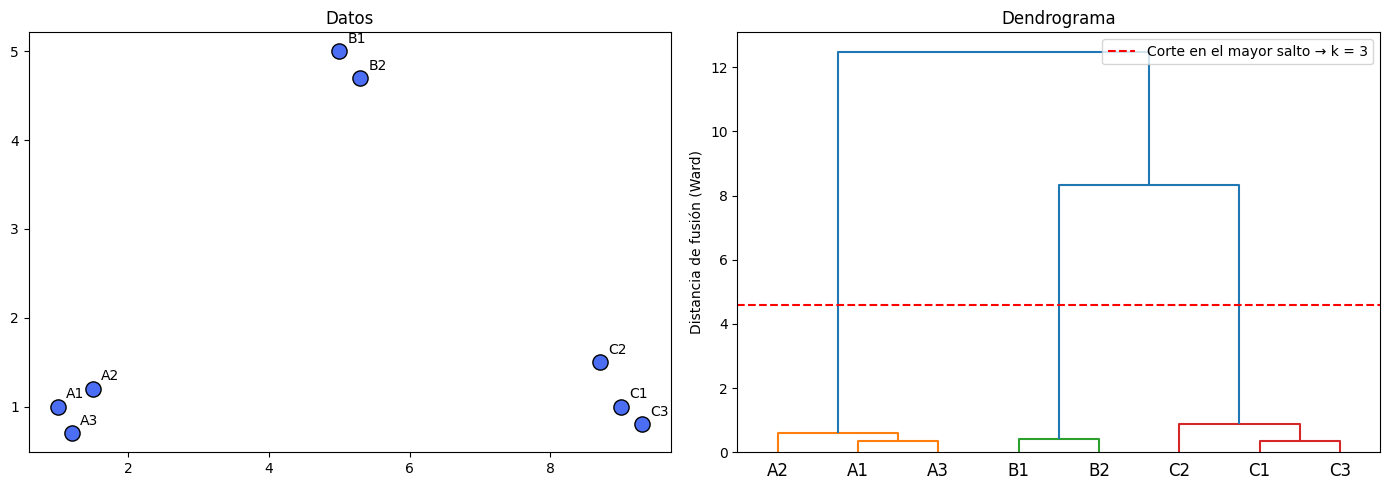

,Índice 1,Índice 2,Distancia,# Datos en el clúster
0,0.0,2.0,0.361,2.0
1,5.0,7.0,0.361,2.0
2,3.0,4.0,0.424,2.0
3,1.0,8.0,0.614,3.0
4,6.0,9.0,0.866,3.0
5,10.0,12.0,8.326,5.0
6,11.0,13.0,12.466,8.0


In [26]:
def k_por_mayor_salto(Z):
    '''
    Retorna el número de clústeres sugerido por el mayor salto entre alturas consecutivas
    de fusión, y la altura de corte (punto medio del salto).

    Parametros:
    Z : np.array
        Matriz de enlace retornada por scipy.cluster.hierarchy.linkage()
    '''
    alturas = Z[:, 2]
    saltos = np.diff(alturas)               # saltos[i-1] = h_{i+1} - h_i  (i fusiones realizadas)
    i = np.argmax(saltos) + 1               # número de fusiones antes del salto
    k = len(alturas) + 1 - i                # N - i clústeres
    altura_corte = (alturas[i - 1] + alturas[i]) / 2
    return k, altura_corte

X_ocho = np.array([[1, 1], [1.5, 1.2], [1.2, 0.7],
                   [5, 5], [5.3, 4.7],
                   [9, 1], [8.7, 1.5], [9.3, 0.8]])
nombres_ocho = ['A1', 'A2', 'A3', 'B1', 'B2', 'C1', 'C2', 'C3']
Z_ocho = linkage(X_ocho, method='ward')
k_ocho, corte_ocho = k_por_mayor_salto(Z_ocho)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(*X_ocho.T, s=120, color='#4C6EF5', edgecolors='black')
for (x, y), n in zip(X_ocho, nombres_ocho):
    axes[0].annotate(n, (x, y), xytext=(6, 6), textcoords='offset points')
axes[0].set_title('Datos')
dendrogram(Z_ocho, labels=nombres_ocho, ax=axes[1], color_threshold=corte_ocho)
axes[1].axhline(corte_ocho, color='red', linestyle='--', label=f'Corte en el mayor salto → k = {k_ocho}')
axes[1].set_ylabel('Distancia de fusión (Ward)')
axes[1].set_title('Dendrograma')
axes[1].legend()
plt.tight_layout()
plt.show()

pd.DataFrame(Z_ocho, columns=['Índice 1', 'Índice 2', 'Distancia', '# Datos en el clúster']).round(3)

La tabla es la **matriz de enlace** que retorna `linkage()`: cada fila es una fusión. Las dos primeras columnas son los índices de los clústeres fusionados (los índices $\ge N$ representan clústeres creados en fusiones anteriores), la tercera es la distancia de fusión y la cuarta es el número de datos del nuevo clúster. Observa el gran salto entre las fusiones dentro de cada grupo y las dos últimas fusiones: por eso el corte sugiere $k = 3$.

### 5.4 Comparación de criterios de enlace

Antes de elegir $k$, comparemos los cuatro criterios de enlace con distintos valores de $k$. Para cada combinación registramos la silueta y el porcentaje de datos en el clúster más grande:

In [27]:
filas = []
for metodo in ['ward', 'complete', 'average', 'single']:
    Z_metodo = linkage(X, method=metodo)     # se calcula una sola vez por criterio
    for k in range(2, 7):
        etq = fcluster(Z_metodo, t=k, criterion='maxclust')
        filas.append({
            'linkage': metodo, 'k': k,
            'silueta': round(silhouette_score(X, etq), 3),
            '% clúster mayor': round(np.bincount(etq).max() / len(X) * 100, 1)
        })
comparacion_enlace = pd.DataFrame(filas)

display(comparacion_enlace.pivot(index='linkage', columns='k', values='silueta')
        .rename_axis('Silueta por k'))
display(comparacion_enlace.pivot(index='linkage', columns='k', values='% clúster mayor')
        .rename_axis('% de datos en el clúster mayor'))

k,2,3,4,5,6
Silueta por k,,,,,
average,0.790,0.726,0.628,0.517,0.463
complete,0.790,0.752,0.721,0.515,0.486
single,0.790,0.726,0.723,0.554,0.466
ward,0.261,0.215,0.223,0.232,0.148


k,2,3,4,5,6
% de datos en el clúster mayor,,,,,
average,100.0,100.0,99.6,99.5,99.5
complete,100.0,99.9,99.9,99.2,99.2
single,100.0,100.0,99.9,99.9,99.9
ward,72.2,50.0,50.0,50.0,26.6


La silueta debe interpretarse junto con el tamaño de los grupos. Algunos enlaces pueden aislar pocos valores extremos y dejar casi todos los datos en un solo grupo. Continuaremos con **Ward**, que busca fusiones con menor aumento de la variación interna.

### 5.5 Selección del hiperparámetro $k$

#### Método de la silueta

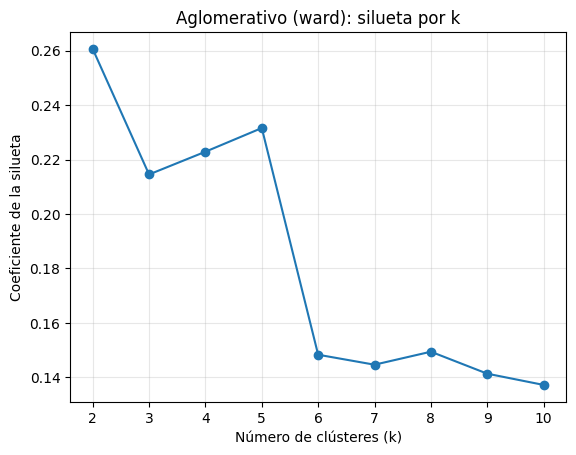

In [28]:
Z_ward = linkage(X, method='ward')

valores_k = range(2, 11)
# fcluster numera los clústeres desde 1; restamos 1 para numerarlos desde 0, como scikit-learn
siluetas_ward = [silhouette_score(X, fcluster(Z_ward, t=k, criterion='maxclust') - 1) for k in valores_k]

plt.plot(list(valores_k), siluetas_ward, marker='o')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Coeficiente de la silueta')
plt.title('Aglomerativo (ward): silueta por k')
plt.grid(alpha=0.3)
plt.show()

#### Dendrograma

Como hay muchas observaciones, mostraremos solo las últimas 30 fusiones. La altura refleja el criterio de fusión de Ward, no simplemente la distancia euclidiana entre grupos. Un salto grande puede orientar el corte, pero no garantiza el mejor número de grupos.

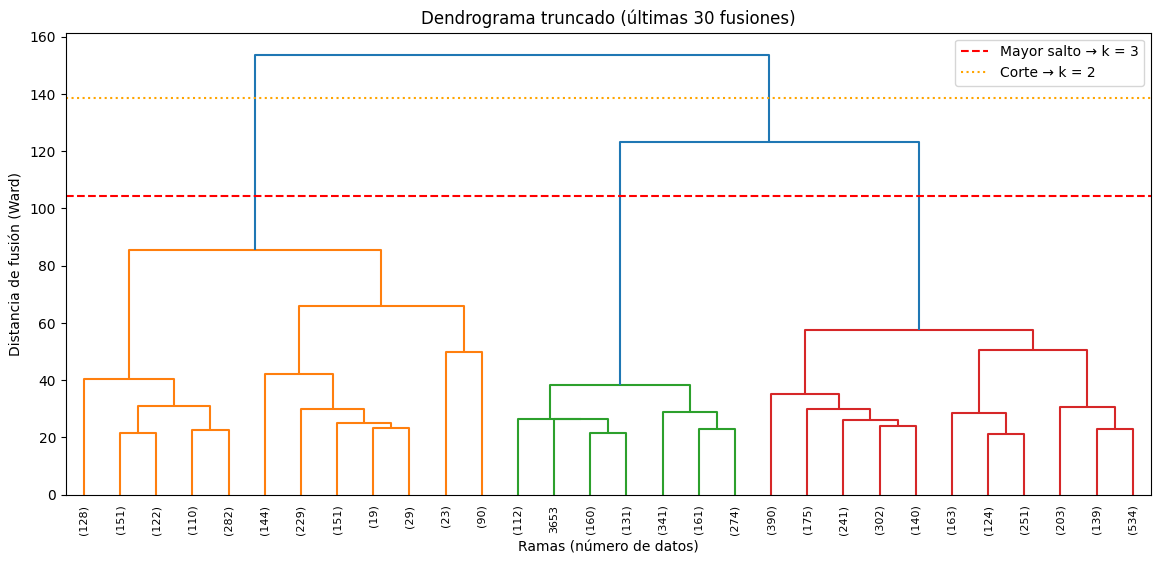

Alturas de las últimas 5 fusiones: [ 57.6  65.9  85.5 123.2 153.7]
El mayor salto entre fusiones consecutivas sugiere k = 3


In [29]:
k_salto, corte_salto = k_por_mayor_salto(Z_ward)
alturas = Z_ward[:, 2]

plt.figure(figsize=(14, 6))
dendrogram(Z_ward, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=8,
           color_threshold=corte_salto)
plt.axhline(corte_salto, color='red', linestyle='--', label=f'Mayor salto → k = {k_salto}')
plt.axhline((alturas[-2] + alturas[-1]) / 2, color='orange', linestyle=':', label='Corte → k = 2')
plt.xlabel('Ramas (número de datos)')
plt.ylabel('Distancia de fusión (Ward)')
plt.title('Dendrograma truncado (últimas 30 fusiones)')
plt.legend()
plt.show()

print('Alturas de las últimas 5 fusiones:', alturas[-5:].round(1))
print(f'El mayor salto entre fusiones consecutivas sugiere k = {k_salto}')

Los dos criterios **no coinciden**: la silueta es máxima con $k=2$, mientras que el mayor salto del dendrograma sugiere $k=3$. Esto es habitual con datos reales, y la elección final debe apoyarse en el objetivo del problema. Revisemos la silueta por dato para ambos casos:

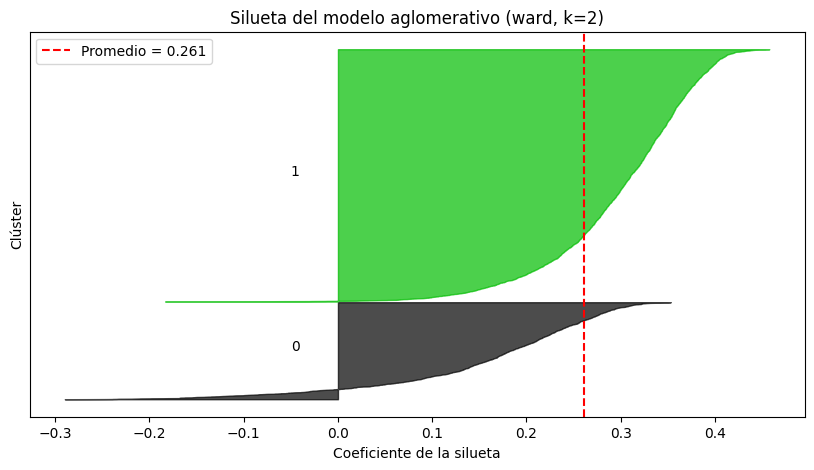

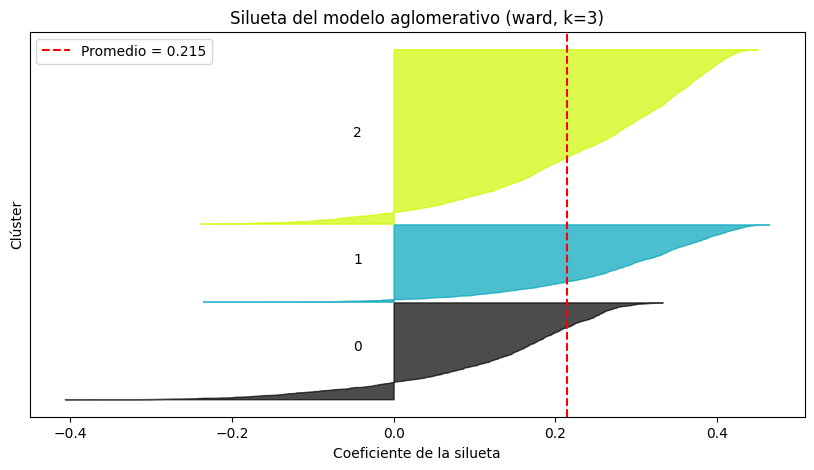

In [30]:
for k in [2, 3]:
    grafico_silueta(X, fcluster(Z_ward, t=k, criterion='maxclust') - 1, f'Silueta del modelo aglomerativo (ward, k={k})')

En ambos casos hay un clúster con una cola de valores negativos: datos que están más cerca de otro clúster que del propio. Al pasar a $k=3$, el clúster más grande se divide en dos subgrupos que también tienen valores negativos en su frontera, y el promedio baja de 0.26 a 0.22. Elegiremos $k=2$ como modelo principal, por tener la mayor silueta y por ser directamente comparable con el resultado de DBSCAN. En los ejercicios analizarás qué representa la subdivisión que aparece con $k=3$.

### 5.6 Entrenamiento del modelo final

Entrenamos el modelo final con la clase `AgglomerativeClustering()` de `scikit-learn`. El resultado es el mismo que obtendríamos cortando el dendrograma de `scipy` en $k=2$:

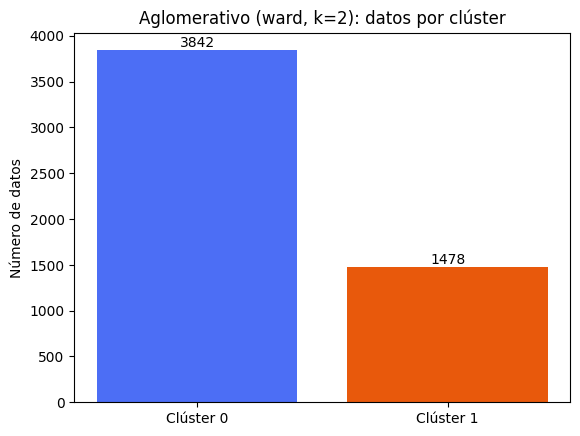

In [31]:
modelo_aglomerativo = AgglomerativeClustering(n_clusters=2, linkage='ward')
etiquetas_aglom = modelo_aglomerativo.fit_predict(X)

valores, conteos = np.unique(etiquetas_aglom, return_counts=True)
barras = plt.bar([f'Clúster {v}' for v in valores], conteos, color=['#4C6EF5', '#E8590C'])
plt.bar_label(barras)
plt.ylabel('Número de datos')
plt.title('Aglomerativo (ward, k=2): datos por clúster')
plt.show()

Observa que el algoritmo aglomerativo asigna todos los datos a algún clúster.

### 5.7. Evaluación del modelo aglomerativo

**Evaluación interna: coeficiente de la silueta**

In [32]:
silueta_aglom = silhouette_score(X, etiquetas_aglom)
print(f'Silueta del modelo aglomerativo (todos los datos): {silueta_aglom:.3f}')

Silueta del modelo aglomerativo (todos los datos): 0.261


**Evaluación externa**: ¿los grupos se relacionan con el color del vino?

In [33]:
tabla_aglom = pd.crosstab(pd.Series(etiquetas_aglom, name='Clúster aglomerativo'), pd.Series(color, name='color'))
display(tabla_aglom)

ari_aglom = adjusted_rand_score(color, etiquetas_aglom)
print(f'ARI con todos los datos: {ari_aglom:.3f}')

color,red,white
Clúster aglomerativo,,
0,22,3820
1,1337,141


ARI con todos los datos: 0.875


También el algoritmo aglomerativo recupera la separación entre vinos tintos y blancos, en este caso asignando **todas** las muestras. Revisa la tabla: ¿cuántos vinos quedaron en el clúster "del otro color"?

### 5.8 Interpretación de los grupos

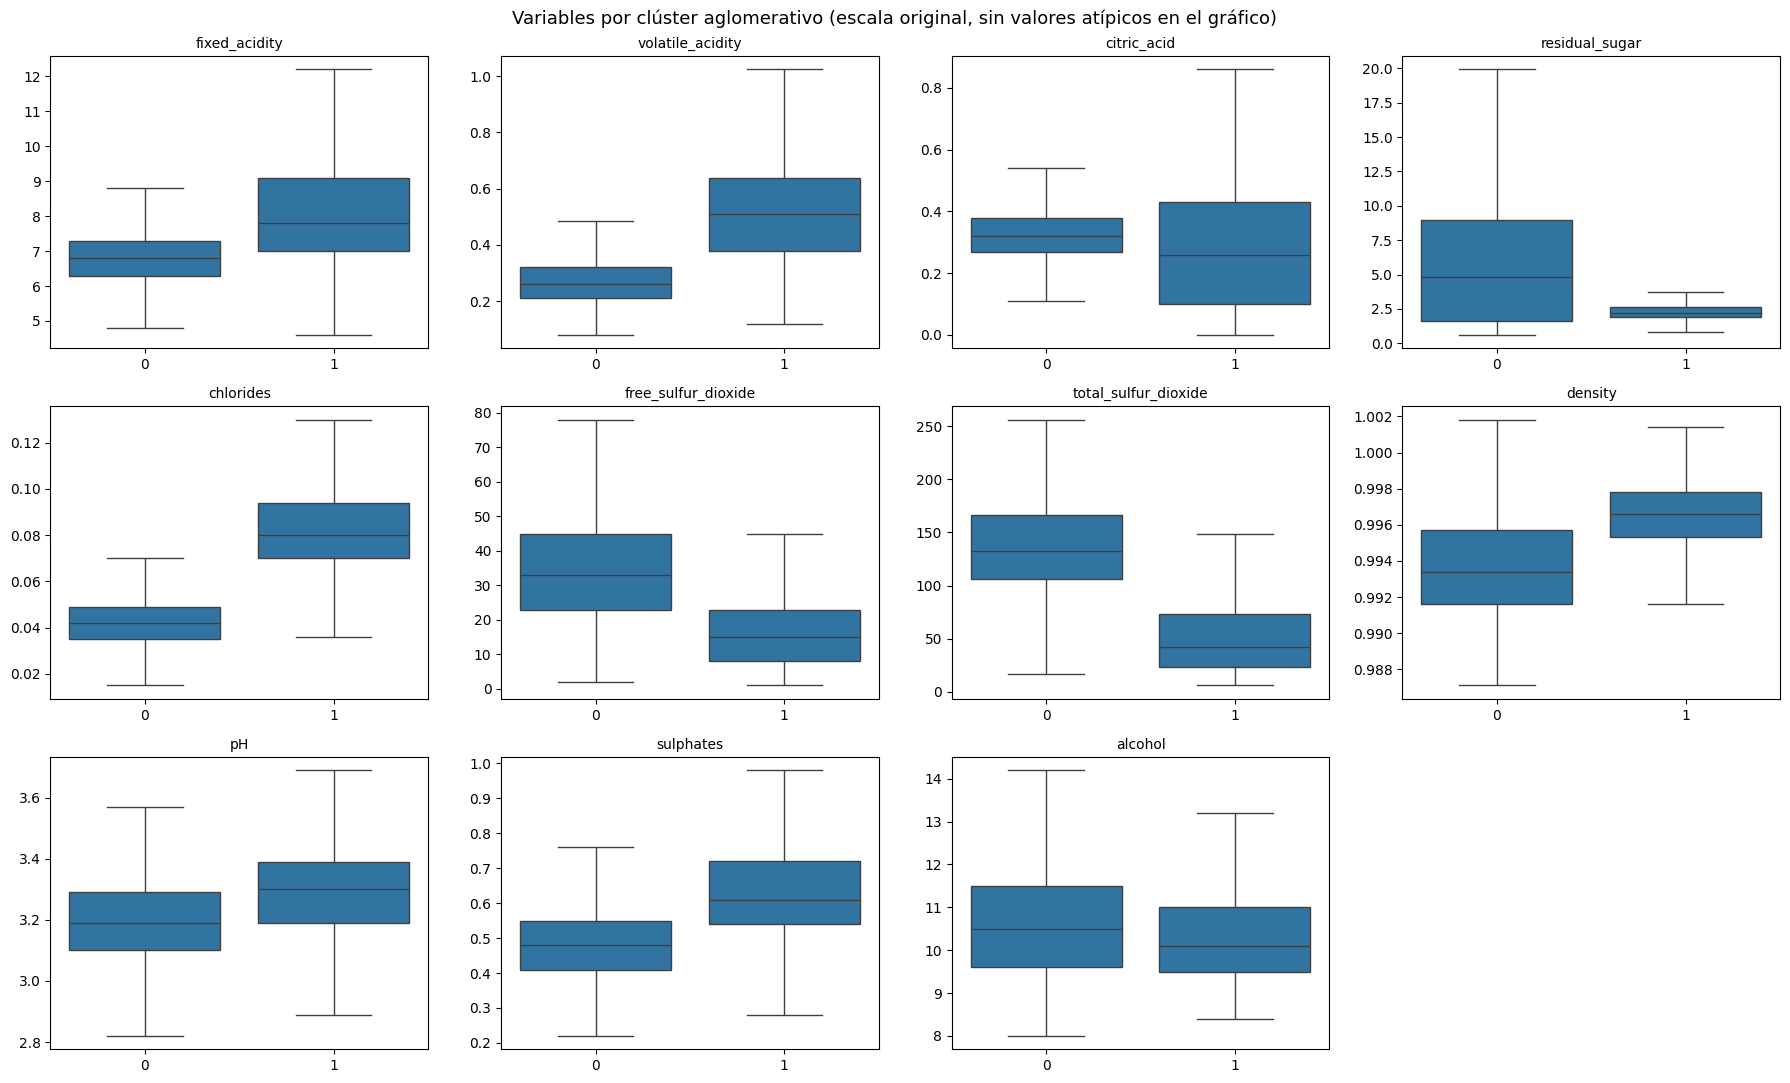

In [34]:
boxplots_por_grupo(X_original, etiquetas_aglom, 'Variables por clúster aglomerativo (escala original, sin valores atípicos en el gráfico)')

> **Para interpretar:**
> * ¿Las variables que diferencian a los clústeres son las mismas que en DBSCAN?
> * Compara la dispersión de las cajas con las de DBSCAN. ¿Por qué podrían ser más amplias aquí? (Pista: ¿dónde quedaron los datos que DBSCAN marcó como ruido?)

## 6. Comparación de los dos modelos

DBSCAN puede excluir observaciones como ruido, mientras que el aglomerativo asigna todas a un grupo. Para comparar las métricas en condiciones similares, también las calcularemos sobre las mismas observaciones, excluyendo el ruido de DBSCAN. El ARI compara con `color`, que no se utilizó en el ajuste.

In [35]:
sil_aglom_mismos = silhouette_score(X[no_ruido], etiquetas_aglom[no_ruido])
ari_aglom_mismos = adjusted_rand_score(color[no_ruido], etiquetas_aglom[no_ruido])

resumen = pd.DataFrame({
    'Hiperparámetros': [f'eps={mejor_eps}, min_samples={mejor_min_samples}', 'k=2'],
    'Clústeres': [len(set(etiquetas_dbscan)) - 1, 2],
    '% ruido': [round(np.mean(etiquetas_dbscan == -1) * 100, 1), 0.0],
    'Silueta (reportada)': [round(silueta_dbscan, 3), round(silueta_aglom, 3)],
    'ARI (todos los datos)': [round(ari_dbscan_todos, 3), round(ari_aglom, 3)],
    'Silueta (mismos datos)': [round(silueta_dbscan, 3), round(sil_aglom_mismos, 3)],
    'ARI (mismos datos)': [round(ari_dbscan_sin_ruido, 3), round(ari_aglom_mismos, 3)],
}, index=['DBSCAN', 'Aglomerativo (ward)'])
resumen

,Hiperparámetros,Clústeres,% ruido,Silueta (reportada),ARI (todos los datos),Silueta (mismos datos),ARI (mismos datos)
DBSCAN,"eps=1.3, min_samples=12",2,29.4,0.298,0.456,0.298,0.986
Aglomerativo (ward),k=2,2,0.0,0.261,0.875,0.298,0.982


Compara las métricas sobre los mismos datos, pero recuerda que valores similares no implican asignaciones idénticas. La tabla cruzada permite examinar qué observaciones reciben grupos diferentes y dónde quedaron las que DBSCAN identificó como ruido.

In [36]:
pd.crosstab(pd.Series(etiquetas_dbscan, name='DBSCAN').replace(-1, 'Ruido'),
            pd.Series(etiquetas_aglom, name='Aglomerativo'))

Aglomerativo,0,1
DBSCAN,,
0,2,773
1,2980,1
Ruido,860,704


### Resumen conceptual

| Aspecto | DBSCAN | Aglomerativo |
|---|---|---|
| Hiperparámetros | `eps`, `min_samples` | Número de clústeres (o altura de corte) y criterio de enlace |
| ¿Requiere fijar $k$? | No | Sí, aunque puede elegirse después de ver el dendrograma |
| Forma de los clústeres | Arbitraria (cadenas de puntos densos) | Depende del enlace (`ward` y `complete` favorecen formas compactas) |
| Datos atípicos | Los marca como ruido (`-1`) | Los asigna a algún clúster |
| Clústeres de densidad distinta | Difícil con un único `eps` | Puede manejarlos según el enlace |
| Costo en memoria | Moderado (consultas de vecindad) | Alto: matriz de distancias $O(N^2)$ |
| Asignar datos nuevos | No tiene `predict()` | No tiene `predict()` |

En este caso, ambos algoritmos descubrieron que la principal estructura de los datos fisicoquímicos corresponde al **tipo de vino**, sin haber usado esa información. DBSCAN aporta además un conjunto de muestras que no pertenecen claramente a ninguno de los dos grupos, lo que responde a la segunda pregunta del laboratorio.

## 7. Reflexión sobre sesgos y el 

Agrupar vinos es un problema de bajo riesgo. Se podría pensar que nadie resulta perjudicado porque una muestra quede en un clúster u otro. Sin embargo, los **mecanismos** que vimos en este tutorial son los mismos que aparecen cuando estos algoritmos se aplican a personas (clientes, pacientes, estudiantes). Esta sección te propone reflexionar sobre ellos.

Primero calculemos algunas cifras del análisis que usaremos en las preguntas:

In [37]:
print(f'Filas duplicadas eliminadas en la preparación (4.1): {n_duplicados / len(data) * 100:.1f}%\n')

ruido_por_color = pd.DataFrame({
    'Muestras': pd.Series(color).value_counts(),
    'Marcadas como ruido': pd.Series(color[etiquetas_dbscan == -1]).value_counts(),
})
ruido_por_color['% marcado como ruido'] = (ruido_por_color['Marcadas como ruido'] / ruido_por_color['Muestras'] * 100).round(1)
ruido_por_color

Filas duplicadas eliminadas en la preparación (4.1): 22.1%



,Muestras,Marcadas como ruido,% marcado como ruido
white,3961,982,24.8
red,1359,582,42.8


Responde las siguientes preguntas usando las cifras de este notebook para justificar tus respuestas.

1. Los vinos tintos se marcan como ruido en una proporción mayor que los blancos, aunque `eps` y `min_samples` son iguales para todas las muestras. Formula al menos dos hipótesis que expliquen esta diferencia (piensa en el tamaño de cada grupo y en su dispersión). ¿Cómo podrías verificar cada hipótesis con los datos?

2. El laboratorio propone enviar a revisión por posible adulteración todas las muestras que DBSCAN marcó como ruido. Según la tabla anterior, ¿qué tipo de productores asumiría una proporción mayor de esas revisiones? ¿Una muestra atípica es necesariamente sospechosa? ¿Qué información adicional debería considerar el laboratorio antes de tomar esa decisión?

3. Transferencia a un contexto con personas. Imagina que el mismo flujo (escalado, DBSCAN y revisión de los datos marcados como atípicos) se aplica a los clientes de un banco para detectar posibles fraudes. ¿Cuáles de los mecanismos de las preguntas anteriores se repetirían? ¿Qué variables podrían funcionar como *proxy* de atributos sensibles, como la edad o el lugar de residencia? ¿Qué cambia cuando quien queda marcado como "atípico" es una persona?

In [38]:
from sklearn.neighbors import NearestNeighbors

vecinos_q = NearestNeighbors(n_neighbors=mejor_min_samples).fit(X)
dist_q, _ = vecinos_q.kneighbors(X)
dist_vecino_12 = dist_q[:, -1]

df_dist_color = pd.DataFrame({'color': color, 'dist_vecino_12': dist_vecino_12})
df_dist_color.groupby('color')['dist_vecino_12'].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
color,,,,,,,,
red,1359.0,1.625,0.652,0.772,1.262,1.466,1.760,9.278
white,3961.0,1.407,0.527,0.578,1.137,1.310,1.553,17.494


**Respuestas**

**1. ¿Por qué los vinos tintos quedan marcados como ruido con mayor frecuencia?**

Los tintos son el grupo más pequeño (1359 muestras, 25.6 % del total) y además, según la distancia al vecino número 12 (el mismo `min_samples` del modelo final) calculada sobre `X`, están más dispersos: su distancia mediana al vecino 12 es 1.466, frente a 1.310 en los blancos (medias de 1.625 y 1.407 respectivamente). Como `eps = 1.3` es un valor fijo para todo el conjunto, más tintos quedan justo por encima de ese radio sin alcanzar los 12 vecinos requeridos, así que no llegan a ser puntos núcleo y terminan como ruido (42.8 % frente a 24.8 % en blancos). Dos hipótesis, entonces:
   - **Tamaño del grupo**: con menos muestras, la densidad local de los tintos es menor incluso si su dispersión relativa fuera igual a la de los blancos, simplemente porque hay menos vecinos potenciales dentro de cualquier radio fijo.
   - **Dispersión del grupo**: los tintos podrían ocupar una región más heterogénea del espacio de variables fisicoquímicas (mayor varianza interna), lo que aumentaría la distancia típica al vecino 12 independientemente del tamaño del grupo.

   Para separarlas, se podría **igualar artificialmente el tamaño de las muestras** (tomar una submuestra aleatoria de blancos del mismo tamaño que los tintos) y volver a calcular la distancia al vecino 12: si la diferencia entre tintos y blancos se reduce mucho, el tamaño del grupo explica la mayor parte del efecto; si se mantiene, la dispersión interna de los tintos pesa más. También se podría comparar directamente la **varianza total** (traza de la matriz de covarianza) de cada color en `X`.

**2. Revisión de las muestras marcadas como ruido.**

Según la tabla, los productores de vino tinto asumirían una proporción claramente mayor de las revisiones (42.8 % de sus muestras, frente a 24.8 % de los blancos), simplemente por ser el grupo más pequeño y disperso, no porque sus vinos sean más sospechosos. Una muestra atípica para DBSCAN **no es necesariamente sospechosa**: el ruido aquí refleja que la combinación de variables fisicoquímicas no cae en una región densamente poblada del conjunto, lo cual puede deberse a un estilo de producción legítimo pero poco común, a una variedad de uva distinta, o a que el grupo de referencia (tintos) es simplemente más pequeño. Antes de decidir destinar esas muestras a revisión, el laboratorio debería considerar al menos: el histórico de cada productor (¿es un patrón nuevo o ya conocido y aceptado?), el tamaño de su grupo de referencia (¿el método penaliza estructuralmente a los grupos minoritarios?), y si existen variables adicionales (procedencia, añada, certificaciones) que expliquen la diferencia sin indicar adulteración.

**3. Transferencia a un banco.**

Los mismos mecanismos se repetirían: un grupo de clientes minoritario en el conjunto de datos (por ejemplo, un segmento demográfico o geográfico poco representado) tendría, solo por su tamaño y posible mayor heterogeneidad interna, una tasa de "ruido" (transacciones u clientes atípicos) más alta que los grupos mayoritarios, sin que eso implique mayor probabilidad real de fraude. Variables como el código postal, el tipo de comercio habitual, el canal de uso del producto (presencial frente a digital) o el rango de edad pueden actuar como *proxies* de atributos sensibles como el nivel socioeconómico, la edad o el origen étnico, incluso si esas variables sensibles nunca se incluyen explícitamente en el modelo. La diferencia clave frente al caso de los vinos es que, cuando quien queda marcado como "atípico" es una persona, las consecuencias (bloqueo de una cuenta, investigación, pérdida de acceso a un servicio) tienen un costo directo y pueden ser discriminatorias si recaen de forma sistemática sobre el mismo grupo demográfico, no por su comportamiento individual sino por la composición del conjunto de entrenamiento.

## 8. Cierre

En este tutorial aplicaste dos enfoques de agrupación. Con DBSCAN identificaste grupos a partir de la densidad y detectaste observaciones aisladas. Con el algoritmo aglomerativo construiste una jerarquía de grupos y exploraste distintos criterios de enlace y números de clústeres.

La comparación mostró que los resultados dependen del algoritmo y de sus hiperparámetros. También permitió comprobar que una buena métrica no garantiza una agrupación útil: es necesario revisar el tamaño de los grupos, sus características y su relación con el problema.

<font size="3">**Ejercicios**</font>

* **Ruido de DBSCAN.** Compara las variables de los datos marcados como ruido con las de los dos clústeres. ¿Son mayoritariamente valores intermedios entre los tintos y los blancos, valores extremos, o ambos? ¿Qué le recomendarías al laboratorio sobre estas muestras?
* **Subdivisión con $k=3$.** Entrena el modelo aglomerativo con $k=3$. ¿Cuál de los dos grupos se subdivide? Usa los diagramas de caja y la variable `quality` (que no usamos para entrenar) para caracterizar los subgrupos. ¿Tiene sentido para el laboratorio trabajar con tres grupos?
* **Duplicados.** Repite el modelado con DBSCAN sin eliminar los duplicados y con los mismos hiperparámetros. ¿Cambian el número de puntos núcleo y el porcentaje de ruido? Explica por qué con base en la definición de punto núcleo.
* **Criterios de selección.** Cambia los criterios de filtrado de la búsqueda de DBSCAN (por ejemplo, permite hasta un 40% de ruido o exige que el clúster menor tenga al menos el 15% de los datos). ¿Cambia la combinación seleccionada? Justifica qué criterios usarías si el objetivo principal del laboratorio fuera **detectar muestras atípicas**.
* **Escalado.** Repite el análisis usando `RobustScaler()` en lugar de `StandardScaler()`. ¿Cambia la escala de valores de `eps` que debes explorar? ¿Por qué?


## Desarrollo de los ejercicios

### Ejercicio 1. Ruido de DBSCAN

Comparamos la mediana de cada variable en el grupo de ruido contra las medianas de los dos clústeres (tabla `medianas_dbscan` de la sección 4.6). Si la mediana del ruido queda **entre** las de los dos clústeres, el patrón es intermedio; si queda **fuera** del rango que forman, es extremo.

In [39]:
cluster_cols = [c for c in medianas_dbscan.columns if c != 'Ruido']

resumen_ruido = medianas_dbscan.copy()
resumen_ruido['mín. entre clústeres'] = medianas_dbscan[cluster_cols].min(axis=1)
resumen_ruido['máx. entre clústeres'] = medianas_dbscan[cluster_cols].max(axis=1)

def clasificar(fila):
    lo, hi = fila['mín. entre clústeres'], fila['máx. entre clústeres']
    v = fila['Ruido']
    return 'Intermedio' if lo <= v <= hi else 'Extremo'

resumen_ruido['Patrón del ruido'] = resumen_ruido.apply(clasificar, axis=1)
resumen_ruido.round(3)

Grupo,0,1,Ruido,mín. entre clústeres,máx. entre clústeres,Patrón del ruido
fixed_acidity,7.700,6.800,7.200,6.800,7.700,Intermedio
volatile_acidity,0.540,0.260,0.360,0.260,0.540,Intermedio
citric_acid,0.220,0.310,0.350,0.220,0.310,Extremo
residual_sugar,2.100,4.600,2.700,2.100,4.600,Intermedio
chlorides,0.078,0.042,0.055,0.042,0.078,Intermedio
free_sulfur_dioxide,13.000,33.000,25.000,13.000,33.000,Intermedio
total_sulfur_dioxide,35.000,130.000,110.000,35.000,130.000,Intermedio
density,0.996,0.993,0.995,0.993,0.996,Intermedio
pH,3.320,3.190,3.200,3.190,3.320,Intermedio
sulphates,0.600,0.470,0.570,0.470,0.600,Intermedio


La tabla muestra que, de las 11 variables, solo `citric_acid` tiene un patrón **extremo**: su mediana en el ruido (0.35) queda por fuera del rango que forman los dos clústeres (0.22 a 0.31), es decir, más alta que en ambos. Las otras 10 variables son **intermedias**: la mediana del ruido cae entre la del clúster 0 (vinos tintos típicos) y la del clúster 1 (vinos blancos típicos). Esto es consistente con lo que ya sugería el ARI más bajo al incluir el ruido (0.456 frente a 0.986 sin él, sección 4.5): buena parte del ruido no corresponde a valores extremos aislados, sino a combinaciones de variables que están a medio camino entre el perfil típico de un tinto y el de un blanco (por ejemplo, niveles de `total_sulfur_dioxide` o `chlorides` intermedios), por lo que no alcanzan la densidad mínima alrededor de ningún centro bien definido. `citric_acid`, en cambio, sí se comporta como un valor genuinamente atípico en el ruido, más alto que en cualquiera de los dos clústeres.

**Recomendación para el laboratorio**: la mayoría del ruido no corresponde a muestras extraordinarias, sino a vinos "híbridos" en varias variables a la vez; antes de tratarlas como sospechosas conviene revisar si corresponden a estilos de producción conocidos (por ejemplo, vinos rosados o técnicas de vinificación poco convencionales) que combinan naturalmente rasgos de tintos y blancos. El patrón extremo de `citric_acid` sí merece una mirada aparte, como posible indicio real de algo distinto.

### Ejercicio 2. Subdivisión con $k=3$

Entrenamos el modelo aglomerativo (ward) con $k=3$ y lo comparamos con el modelo de $k=2$ mediante una tabla cruzada, para identificar cuál de los dos clústeres originales se subdivide. Luego caracterizamos los subgrupos con los diagramas de caja y con `quality`, variable que no se usó para entrenar ningún modelo.

In [40]:
modelo_aglom_k3 = AgglomerativeClustering(n_clusters=3, linkage='ward')
etiquetas_aglom_k3 = modelo_aglom_k3.fit_predict(X)

tabla_k2_vs_k3 = pd.crosstab(pd.Series(etiquetas_aglom, name='Clúster (k=2)'),
                             pd.Series(etiquetas_aglom_k3, name='Clúster (k=3)'))
display(tabla_k2_vs_k3)

Clúster (k=3),0,1,2
Clúster (k=2),,,
0,0,2662,1180
1,1478,0,0


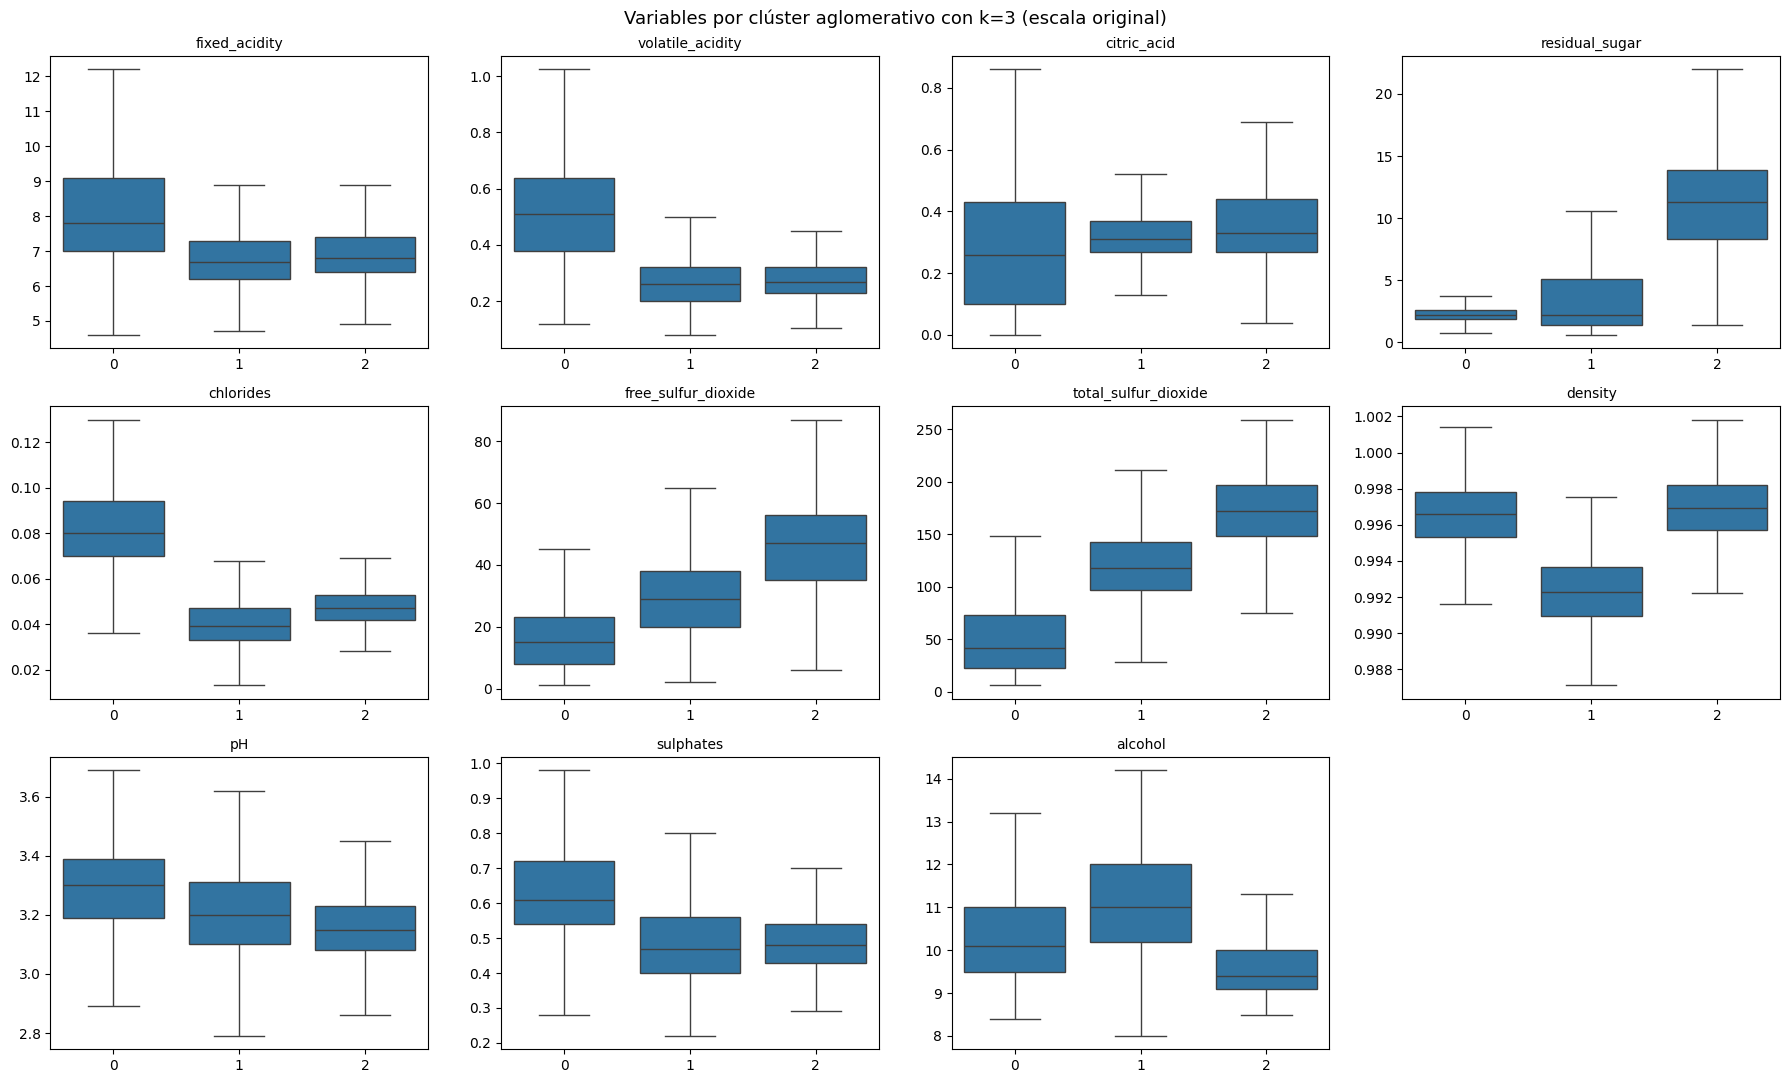

In [41]:
boxplots_por_grupo(X_original, etiquetas_aglom_k3,
                   'Variables por clúster aglomerativo con k=3 (escala original)')

In [42]:
quality = etiquetas_externas['quality'].values
df_calidad_k3 = pd.DataFrame({'Clúster (k=3)': etiquetas_aglom_k3, 'quality': quality})
df_calidad_k3.groupby('Clúster (k=3)')['quality'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Clúster (k=3),,,,,,,,
0,1478.0,5.59,0.83,3.0,5.0,6.0,6.0,8.0
1,2662.0,6.01,0.92,3.0,5.0,6.0,7.0,9.0
2,1180.0,5.57,0.72,3.0,5.0,6.0,6.0,9.0


La tabla cruzada muestra que el clúster 0 de $k=2$ (3842 muestras = 2662 + 1180) es el que se **subdivide** al pasar a $k=3$, en dos subgrupos de 2662 y 1180 observaciones. El clúster 1 de $k=2$ (1478 muestras) se mantiene intacto: todas sus observaciones quedan juntas en un único subgrupo de $k=3$, sin dividirse.

Mirando `quality` (que no se usó para entrenar ningún modelo), los tres subgrupos de $k=3$ tienen medianas de calidad muy parecidas (6 en los tres casos), pero el subgrupo 1 (2662 muestras, resultado de la división) tiene una **media más alta** (6.01) que los subgrupos 0 y 2 (5.59 y 5.57), y también el percentil 75 más alto (7 frente a 6). Esto sugiere que la subdivisión no separa vinos "buenos" de "malos" de forma tajante, pero sí aísla un subgrupo con una cola más pesada hacia calidades altas dentro del clúster grande original.

**¿Tiene sentido trabajar con tres grupos?** Depende del objetivo: si el laboratorio solo quiere distinguir tintos de blancos (la pregunta original del problema), $k=2$ ya captura esa estructura con una silueta más alta (sección 5.5). Si además le interesa identificar, dentro del grupo mayoritario, un subperfil asociado a calidades algo más altas, $k=3$ aporta esa distinción adicional, aunque la diferencia en `quality` entre los subgrupos es modesta y no debería interpretarse como una separación clara de calidad.

### Ejercicio 3. Duplicados

Repetimos el ajuste de DBSCAN con los mismos hiperparámetros (`mejor_eps`, `mejor_min_samples`) pero **sin** eliminar las filas duplicadas (releemos el archivo original). Usamos el mismo `scaler` ya ajustado, porque la pregunta es el efecto de los duplicados sobre DBSCAN con una escala fija, no el efecto sobre el escalado en sí.

In [43]:
df_con_duplicados = pd.read_csv('data/Wine_quality_Data.csv', sep=',')
X_dup_original = df_con_duplicados[variables]
X_dup = scaler.transform(X_dup_original)

modelo_dbscan_dup = DBSCAN(eps=mejor_eps, min_samples=mejor_min_samples)
etiquetas_dbscan_dup = modelo_dbscan_dup.fit_predict(X_dup)

n_nucleo_dup = len(modelo_dbscan_dup.core_sample_indices_)
n_ruido_dup = int(np.sum(etiquetas_dbscan_dup == -1))

comparacion_duplicados = pd.DataFrame({
    'Sin eliminar duplicados': [len(X_dup), n_nucleo_dup, round(n_nucleo_dup / len(X_dup) * 100, 1),
                                n_ruido_dup, round(n_ruido_dup / len(X_dup) * 100, 1)],
    'Duplicados eliminados (modelo original)': [len(X), n_nucleo, round(n_nucleo / len(X) * 100, 1),
                                                 n_ruido, round(n_ruido / len(X) * 100, 1)],
}, index=['Muestras', 'Puntos núcleo', '% núcleo', 'Puntos de ruido', '% ruido'])
comparacion_duplicados

,Sin eliminar duplicados,Duplicados eliminados (modelo original)
Muestras,6497.0,5320.0
Puntos núcleo,3353.0,2328.0
% núcleo,51.6,43.8
Puntos de ruido,1662.0,1564.0
% ruido,25.6,29.4


Sin eliminar duplicados, el conjunto tiene 6497 muestras (1177 más que las 5320 del modelo original) y DBSCAN, con los mismos `eps=1.3` y `min_samples=12`, encuentra **más puntos núcleo en términos absolutos** (3353 frente a 2328) pero también **más puntos de ruido** (1662 frente a 1564), y el porcentaje de ruido en realidad **baja** levemente (25.6 % frente a 29.4 %), mientras que el porcentaje de puntos núcleo sube (51.6 % frente a 43.8 %).

Esto es consistente con la definición de punto núcleo: un punto es núcleo si tiene al menos `min_samples` vecinos (incluido él mismo) dentro de un radio `eps`. Una fila duplicada agrega una copia exacta de una observación ya existente, que queda a distancia 0 de su original y por tanto siempre está dentro de su $\varepsilon$-vecindad. Si un punto original tenía, por ejemplo, 10 vecinos (menos que `min_samples=12`) y existen varias copias duplicadas de él o de alguno de sus vecinos cercanos, esas copias **inflan artificialmente el conteo de vecinos** tanto del punto original como de sus propias copias, lo que puede convertir a puntos que antes no eran núcleo en puntos núcleo. Por esto el porcentaje de núcleo sube: los duplicados concentran densidad extra exactamente en las zonas donde ya había puntos (no la reparten uniformemente), favoreciendo a las regiones ya pobladas y dejando relativamente igual o incluso reduciendo, en términos porcentuales, el peso del ruido.

### Ejercicio 4. Criterios de selección

Repetimos el filtro de la sección 4.3 (paso 3) con dos variantes: un criterio más **laxo** (hasta 40 % de ruido, sin exigir un tamaño mínimo al clúster menor) y uno más **estricto** (clúster menor con al menos 15 % de los datos y máximo 30 % de ruido, el mismo límite de ruido que el criterio original pero más exigente en balance).

In [44]:
candidatos_laxos = resultados_dbscan[
    (resultados_dbscan['clústeres encontrados'] >= 2) &
    (resultados_dbscan['% ruido'] <= 40)
].sort_values('silueta (sin ruido)', ascending=False)
print('Criterio laxo (hasta 40% de ruido, sin mínimo de tamaño):')
display(mostrar_busqueda(candidatos_laxos.head(5)))

candidatos_estrictos = resultados_dbscan[
    (resultados_dbscan['clústeres encontrados'] >= 2) &
    (resultados_dbscan['% clúster menor'] >= 15) &
    (resultados_dbscan['% ruido'] <= 30)
].sort_values('silueta (sin ruido)', ascending=False)
print(f'\nCriterio estricto (clúster menor >= 15%, ruido <= 30%): {len(candidatos_estrictos)} combinaciones cumplen')
display(mostrar_busqueda(candidatos_estrictos.head(5)))

print(f"\nMejor combinación con el criterio original: eps={mejor_eps}, min_samples={mejor_min_samples}")

Criterio laxo (hasta 40% de ruido, sin mínimo de tamaño):


Hiperparámetros                        Resultados                          \
               eps min_samples clústeres encontrados % ruido % clúster menor   
15             2.6          12                     2     1.1             0.2   
16             2.7          12                     2     0.9             0.2   
17             2.8          12                     2     0.8             0.2   
2              1.3          12                     2    29.4            14.6   
21             1.4          22                     2    27.7            14.6   

                        
   silueta (sin ruido)  
15               0.626  
16               0.625  
17               0.624  
2                0.298  
21               0.296


Criterio estricto (clúster menor >= 15%, ruido <= 30%): 0 combinaciones cumplen


Empty DataFrame
Columns: [(Hiperparámetros, eps), (Hiperparámetros, min_samples), (Resultados, clústeres encontrados), (Resultados, % ruido), (Resultados, % clúster menor), (Resultados, silueta (sin ruido))]
Index: []


Mejor combinación con el criterio original: eps=1.3, min_samples=12


Con el criterio **laxo** (hasta 40 % de ruido, sin exigir tamaño mínimo al clúster menor), la combinación seleccionada cambia por completo: la mayor silueta (0.626) corresponde a `eps=2.6, min_samples=12`, con apenas 1.1 % de ruido y un clúster menor de solo 0.2 % de los datos. Es decir, sin el requisito de tamaño mínimo, la búsqueda prefiere un `eps` grande que prácticamente fusiona todo en un solo clúster gigantesco más un puñado de puntos sueltos etiquetados como un "segundo clúster" de tamaño casi nulo. La silueta es alta porque ese clúster diminuto está muy separado del resto, pero la partición resultante no es útil para distinguir tintos de blancos ni para ningún otro propósito práctico: es un óptimo espurio de la métrica, exactamente el riesgo que el requisito de `% clúster menor >= 5` buscaba evitar en la sección 4.3.

Con el criterio **estricto** (clúster menor con al menos 15 % de los datos y ruido ≤ 30 %), **ninguna combinación cumple**: el mejor candidato original (`eps=1.3, min_samples=12`) tiene un clúster menor de 14.6 %, apenas por debajo del 15 % exigido. Esto muestra lo sensible que es la selección a umbrales que parecen arbitrarios: mover el límite un punto porcentual cambia por completo el resultado de la búsqueda, de "hay una solución razonable" a "no hay ninguna".

**Si el objetivo fuera detectar muestras atípicas**, no conviene maximizar la silueta a toda costa (como hace el criterio laxo) ni exigir balance entre clústeres (como el estricto): lo importante es que el porcentaje de ruido sea lo bastante bajo para que las observaciones marcadas sean realmente poco frecuentes (y no la mayoría de un clúster mal definido), pero lo bastante alto para que el conjunto de ruido sea manejable y no se reduzca a un par de puntos triviales como en el criterio laxo. En ese caso usaría un criterio centrado en el `% ruido` (por ejemplo, entre 5 % y 20 %) más que en el tamaño del clúster menor, y revisaría manualmente las observaciones marcadas en lugar de confiar solo en la silueta.

### Ejercicio 5. Escalado

Repetimos el escalado con `RobustScaler()` (que usa la mediana y el rango intercuartílico, menos sensible a valores extremos que `StandardScaler()`) y comparamos el gráfico de k-distancias y el valor del codo resultante.

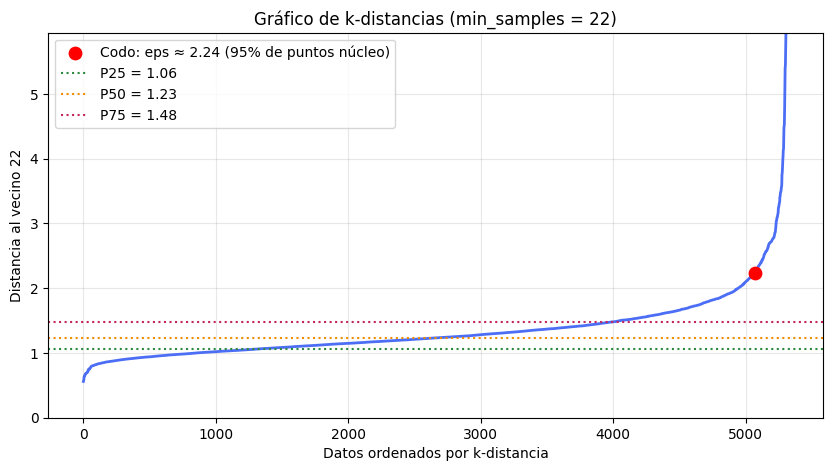

StandardScaler: eps en el codo ≈ 2.76 (rango explorado: 1.1 a 2.8)
RobustScaler:   eps en el codo ≈ 2.24


In [45]:
from sklearn.preprocessing import RobustScaler

robust_scaler = RobustScaler()
X_robust = robust_scaler.fit_transform(X_original)

dist_k_robust, eps_codo_robust = grafico_k_distancias(X_robust, min_samples_base)

print(f'StandardScaler: eps en el codo ≈ {eps_codo:.2f} (rango explorado: {eps_min} a {eps_max})')
print(f'RobustScaler:   eps en el codo ≈ {eps_codo_robust:.2f}')

Con `RobustScaler()` el codo del gráfico de k-distancias aparece en `eps ≈ 2.24`, un valor más bajo que el `eps ≈ 2.76` obtenido con `StandardScaler()` (ambos con `min_samples_base = 22`). Esto tiene sentido: `RobustScaler()` centra con la mediana y escala con el rango intercuartílico, en lugar de la media y la desviación estándar. Como varias variables de este conjunto tienen valores extremos marcados (`residual_sugar`, `chlorides`, `free_sulfur_dioxide`, vistos en la sección 2), `StandardScaler()` infla su desviación estándar por culpa de esos extremos, lo que "comprime" la mayoría de los datos hacia valores escalados pequeños y deja una cola larga de valores grandes; eso alarga las distancias típicas entre vecinos. `RobustScaler()`, al ignorar los percentiles más extremos en su cálculo de escala, no sufre esa compresión y las distancias entre la mayoría de los puntos (los que no son extremos) resultan más pequeñas en términos relativos, lo que se traduce en una escala de `eps` más baja.

En la práctica, esto significa que si se usa `RobustScaler()` habría que **repetir la búsqueda en grilla con un rango de `eps` distinto** (más bajo) al de la sección 4.3; usar el mismo rango de antes llevaría a valores de `eps` demasiado grandes en relación con la nueva escala, y DBSCAN tendería a fusionar todo en un único clúster.